# Imports

In [62]:
import numpy as np
import pandas as pd
import matplotlib.pylab as plt
import matplotlib.dates as mdates
import seaborn as sns

# Fonte de dados para analise

- https://medium.com/@renata-biaggi/guia-completo-an%C3%A1lise-explorat%C3%B3ria-de-dados-com-python-2964fa2940f4

# EDA

## Entendendo a base de dados

In [45]:
def transformar_dataset_to_csv(path, path_save, nome):

    colunas = ["id", "date", "Temperature", "Humidity", "Light", "CO2", "HumidityRatio", "Occupancy"]
    colunas_sem_id = ["date", "Temperature", "Humidity", "Light", "CO2", "HumidityRatio", "Occupancy"]
    
    dataset = pd.read_csv(
        path,
        header = 0,
        names = colunas,
        usecols = colunas_sem_id,
        parse_dates = ["date"],
    )

    dataset.to_csv(path_save + f"/{nome}.csv", index=False)
    
    return dataset
    
datatest = transformar_dataset_to_csv("./dataset/occupancy_detection/dataset_txt/datatest.txt", "./dataset/occupancy_detection/dataset_csv", "datatest")
datatest2 = transformar_dataset_to_csv("./dataset/occupancy_detection/dataset_txt/datatest2.txt", "./dataset/occupancy_detection/dataset_csv", "datatest2")
datatraining = transformar_dataset_to_csv("./dataset/occupancy_detection/dataset_txt/datatraining.txt", "./dataset/occupancy_detection/dataset_csv", "datatraining")

In [ ]:
dataset_completo = pd.concat([datatest, datatraining, datatest2])

In [ ]:
datasets = [datatest, datatraining, datatest2, dataset_completo]

In [48]:
dataset_completo.to_csv("./dataset/occupancy_detection/dataset_csv/dataset_completo.csv")

In [49]:
def resumo_dataset(dataset, nome):
    linha = "=" * 70

    print(linha)
    print(f"Resumo sem graficos do Dataset de Detecção de Ocupação: {nome}")
    print(linha)

    linhas, colunas = dataset.shape
    print(f"\nDimensões: {linhas:,} linhas × {colunas} colunas")

    print(f"\nColunas ({colunas}):")
    for i, (col, dtype) in enumerate(zip(dataset.columns, dataset.dtypes), start=1):
        print(f"{i:>2}.{col:<20} → {dtype}")

    print("A ultima linha é a linha que queremos prever")
    
    print("\nResumo de Escalas:")
    
    num = dataset.select_dtypes(include=[np.number])
    resumo = pd.DataFrame({
        "min":   num.min(),
        "max":   num.max(),
        "range": num.max() - num.min(),
        "std":   num.std(),
    })
    print(f"\n{'Coluna':<20}  {'min':>10}  {'max':>10}  {'range':>12}  {'std':>10}")
    print("-" * 78)

    for col, r in resumo.iterrows():
        print(f"{col:<20}  {r['min']:>10.4f}  {r['max']:>10.4f}  "
              f"{r['range']:>12.4f}  {r['std']:>10.4f}")

    print("\nValores nulos por coluna:")
    nulos = dataset.isnull().sum()
    for col, qtd in nulos.items():
        pct = 100 * qtd / len(dataset)
        marca = "✅" if qtd == 0 else "⚠️"
        print(f"   {marca} {col:<20} {qtd:>6} ({pct:5.2f}%)")

    print("\nPrimeiras 5 linhas:")
    print(dataset.head().to_string())

    print("\nEstatísticas descritivas:")
    print(dataset.describe().round(3).to_string())

    print("\nDados Duplicados:")
    print(dataset.duplicated().sum())

    print("\nDistribuição das Classes:")
    dataset_classes = dataset['Occupancy']

    contagem   = dataset_classes.value_counts().sort_index()
    percentual = dataset_classes.value_counts(normalize=True).sort_index() * 100

    print(f"\n{'Classe':<14}{'Qtd':>12}{'%':>10}")

    for classe in contagem.index:
        print(f"{classe:<14}{contagem[classe]:>12}{percentual[classe]:>9.2f}%")

    print("\n" + linha)
    

In [50]:
resumo_dataset(datatraining, "datatraining")
resumo_dataset(datatest, "datatest")
resumo_dataset(datatest2, "datatest2")
resumo_dataset(dataset_completo, "dataset_completo")

Resumo sem graficos do Dataset de Detecção de Ocupação: datatraining

Dimensões: 8,143 linhas × 7 colunas

Colunas (7):
 1.date                 → datetime64[us]
 2.Temperature          → float64
 3.Humidity             → float64
 4.Light                → float64
 5.CO2                  → float64
 6.HumidityRatio        → float64
 7.Occupancy            → int64
A ultima linha é a linha que queremos prever

Resumo de Escalas:

Coluna                       min         max         range         std
------------------------------------------------------------------------------
Temperature              19.0000     23.1800        4.1800      1.0169
Humidity                 16.7450     39.1175       22.3725      5.5312
Light                     0.0000   1546.3333     1546.3333    194.7558
CO2                     412.7500   2028.5000     1615.7500    314.3209
HumidityRatio             0.0027      0.0065        0.0038      0.0009
Occupancy                 0.0000      1.0000        1.0000      0.

### Dicionário de variáveis

| Coluna | Descrição | Faixa | Precisão | Resolução | Sensor |
|---|---|---|---|---|---|
| `date` | Timestamp da medição | — | — | 1 min (no dataset) | — |
| `Temperature` | Temperatura do ar (°C) | −40 a 80 °C | ± 0,5 °C | 0,1 °C | DHT22 |
| `Humidity` | Umidade relativa do Ar (%) | 0 a 100 % RH | ± 3 % RH | 0,1 % RH | DHT22 |
| `Light` | Quantidade de Luz no ambiente - Iluminância | 1 a 40 000 lux | N/A | 1 lux | TSL2561 |
| `CO2` | Concentração de CO₂ (ppm) | 0 a 2000 ppm | ± 30 ppm (400–1250 ppm)<br>± 5 % da leitura + 30 ppm (1250–2000 ppm) | 1 ppm | Telaire 6613 |
| `HumidityRatio` | Razão de umidade (kg de vapor / kg de ar seco) — **derivada** de `Temperature` e `Humidity` | — | — | — | — (derivada) |
| `Occupancy` | Variável-alvo binária (1 = ocupado, 0 = vazio) | {0, 1} | — | binária | — (rótulo) |

In [51]:
for dataset in datasets:

    dia_semana = dataset['date'].dt.day_of_week 
    dataset["hora"] = dataset["date"].dt.hour
    dataset['date_dia_semana_sin'] = np.sin(2 * np.pi * dia_semana / 7.0)
    dataset['date_dia_semana_cos'] = np.cos(2 * np.pi * dia_semana / 7.0)

    hora = dataset['date'].dt.hour
    dataset['date_hora_sin'] = np.sin(2 * np.pi * hora / 24.0)
    dataset['date_hora_cos'] = np.cos(2 * np.pi * hora / 24.0)

# Analise das features numericas do dataset em grafico

In [52]:
features_numericas = ["Temperature", "Humidity", "Light", "CO2", "HumidityRatio", "Occupancy", 'date_hora_sin', 'date_hora_cos', 'date_dia_semana_sin', 'date_dia_semana_cos']


<Figure size 1500x1500 with 0 Axes>

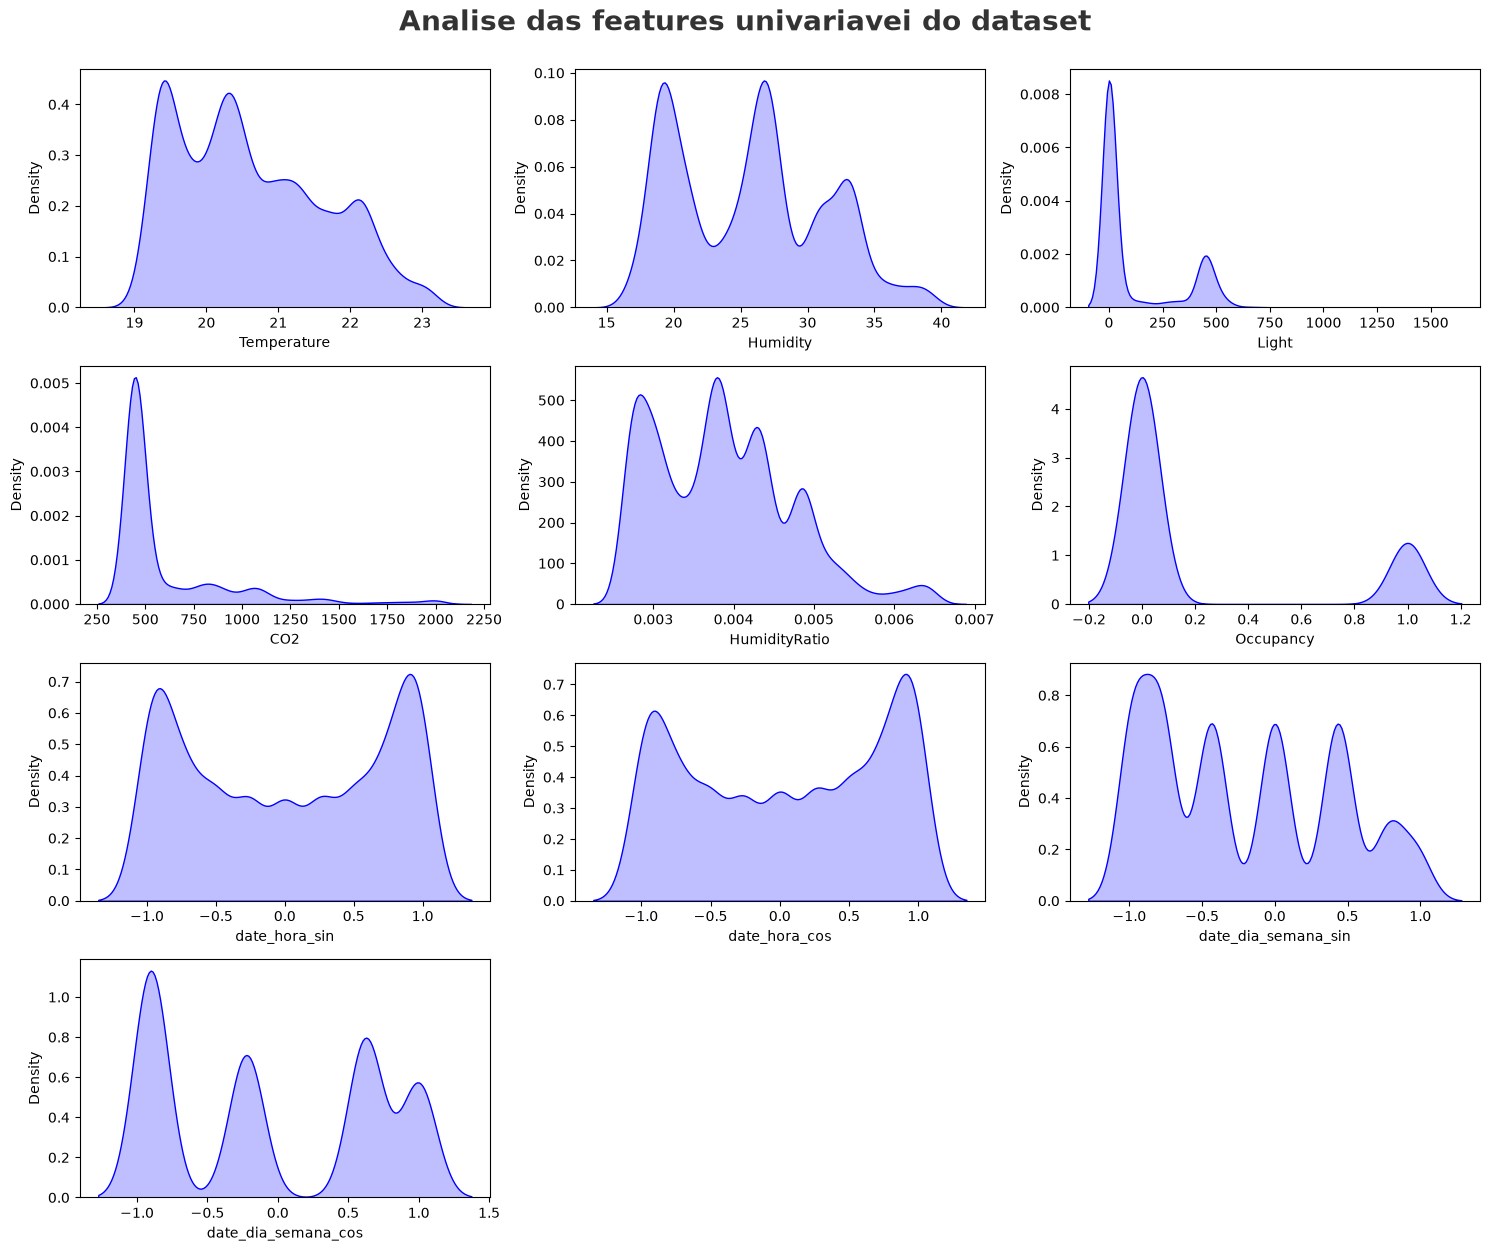

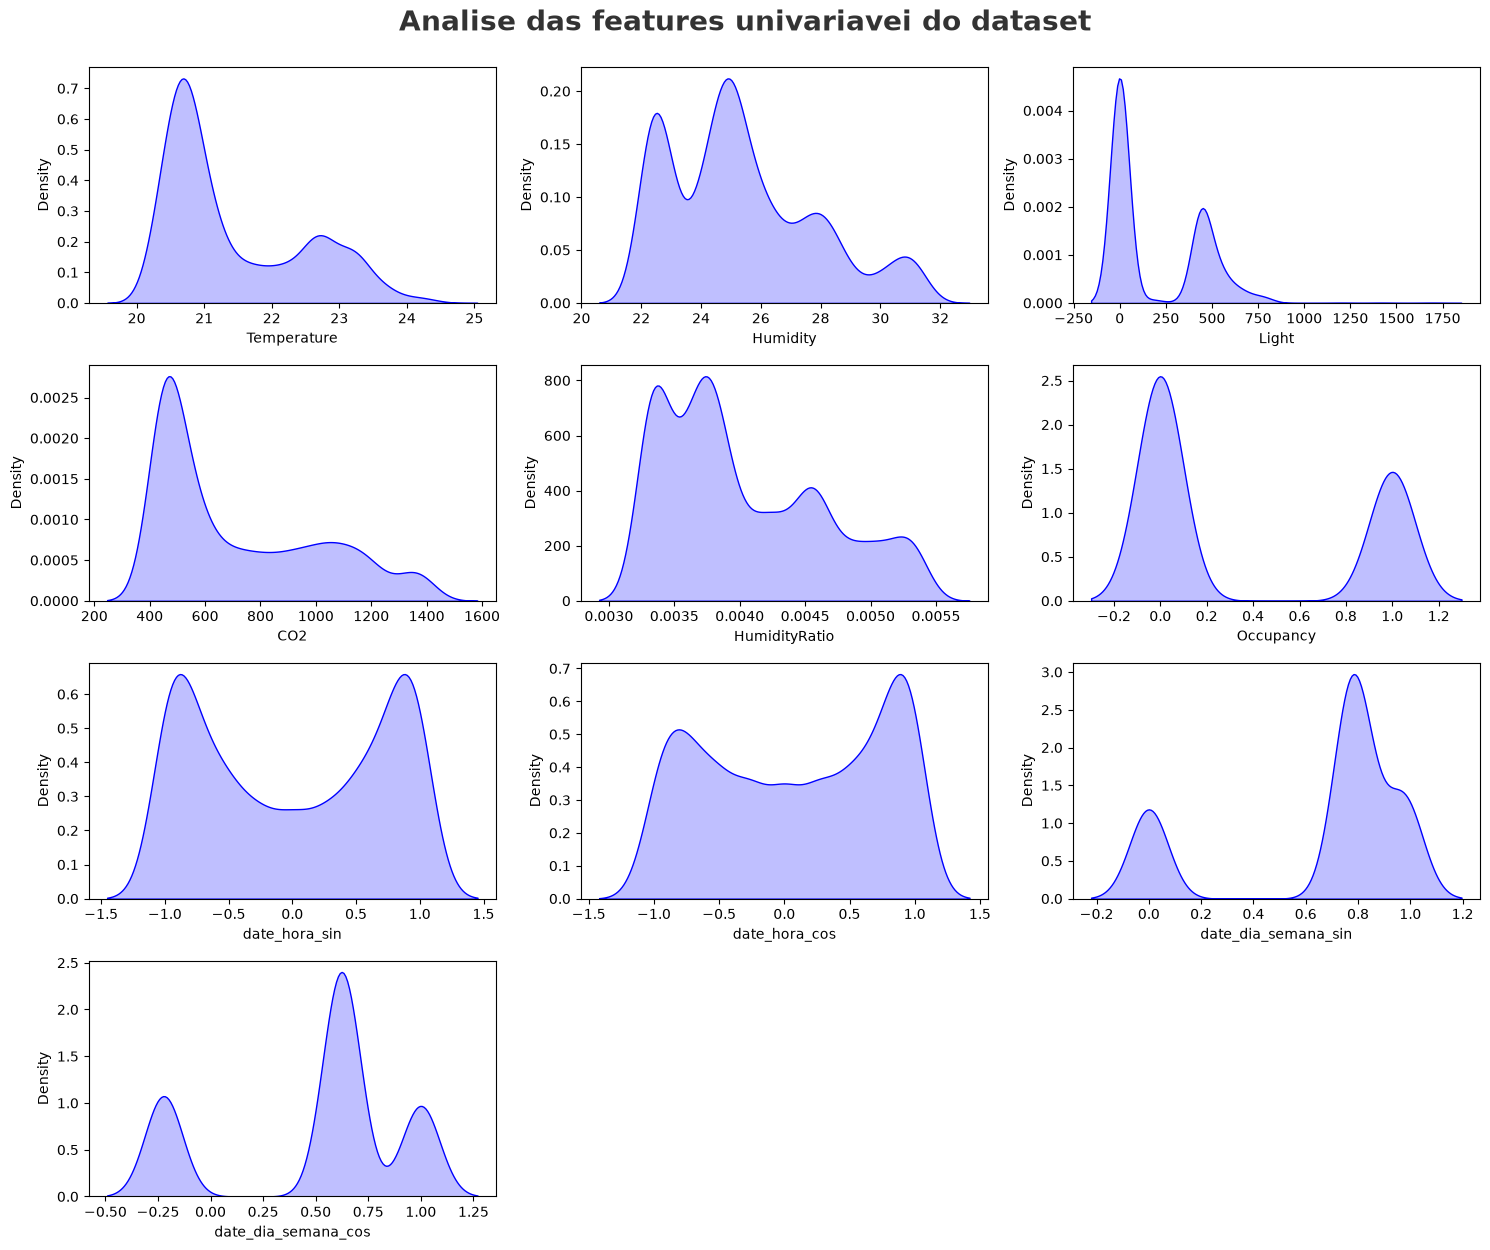

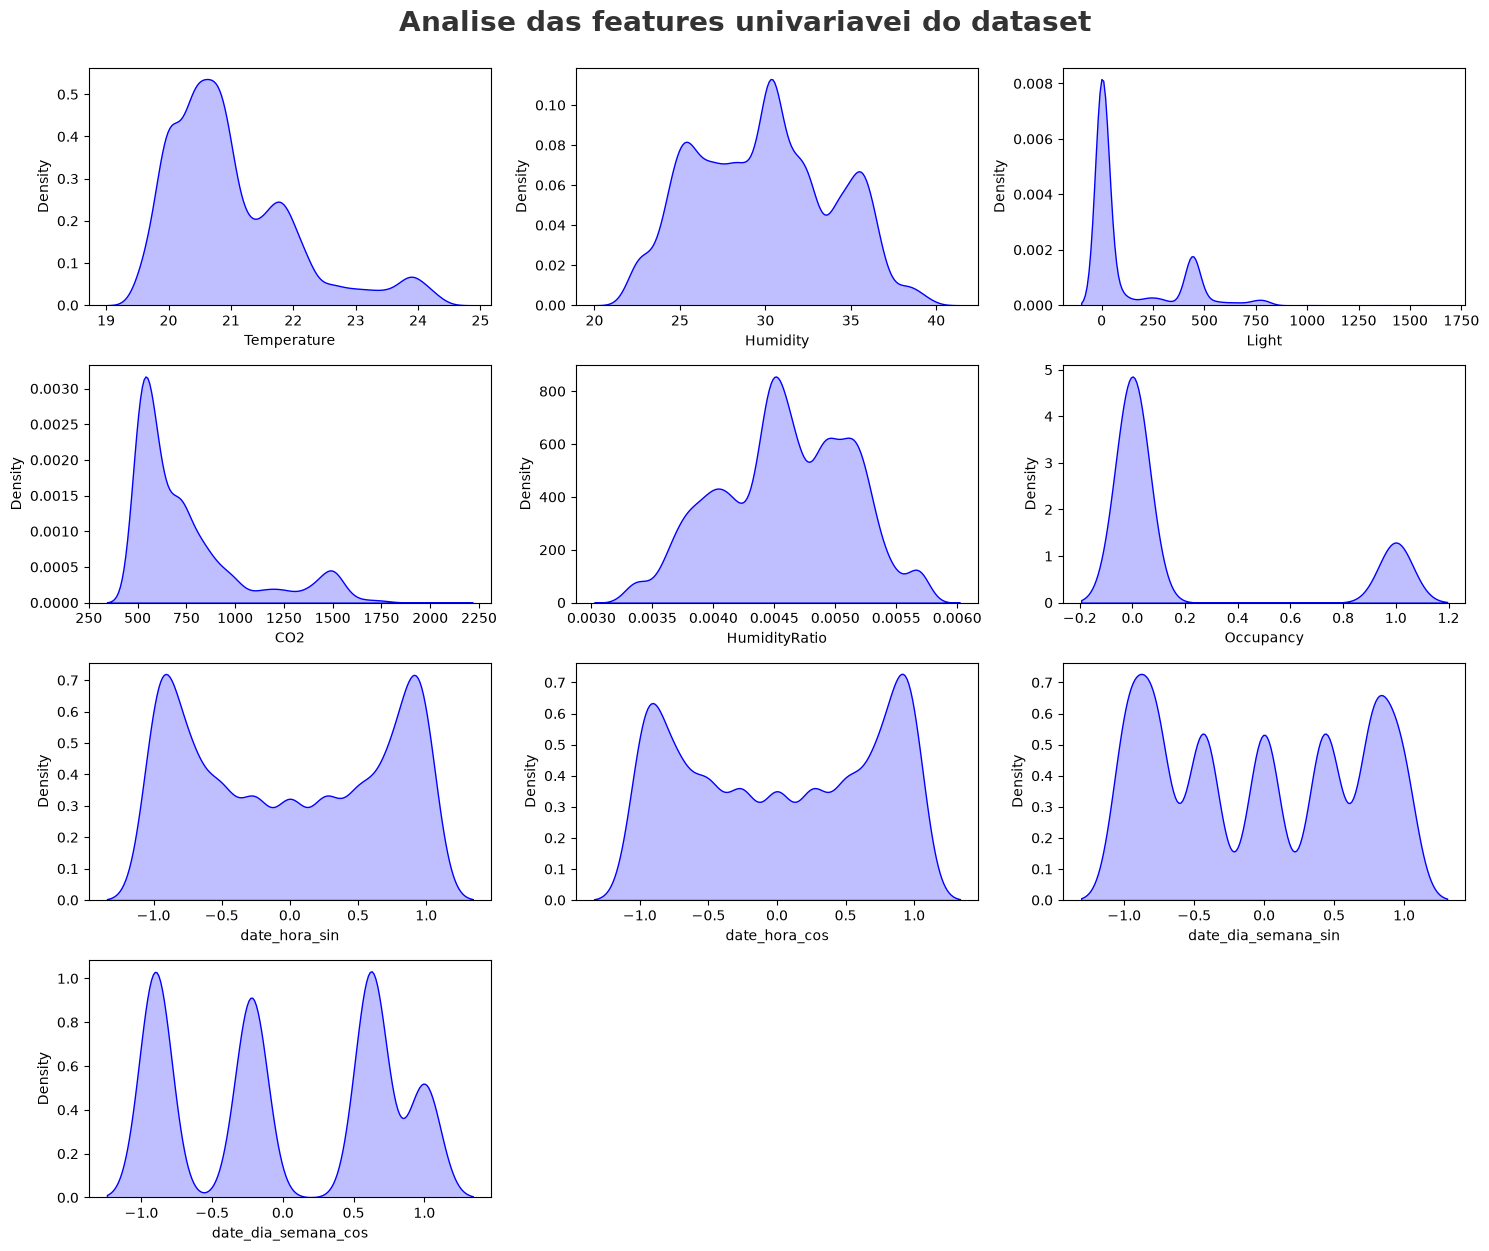

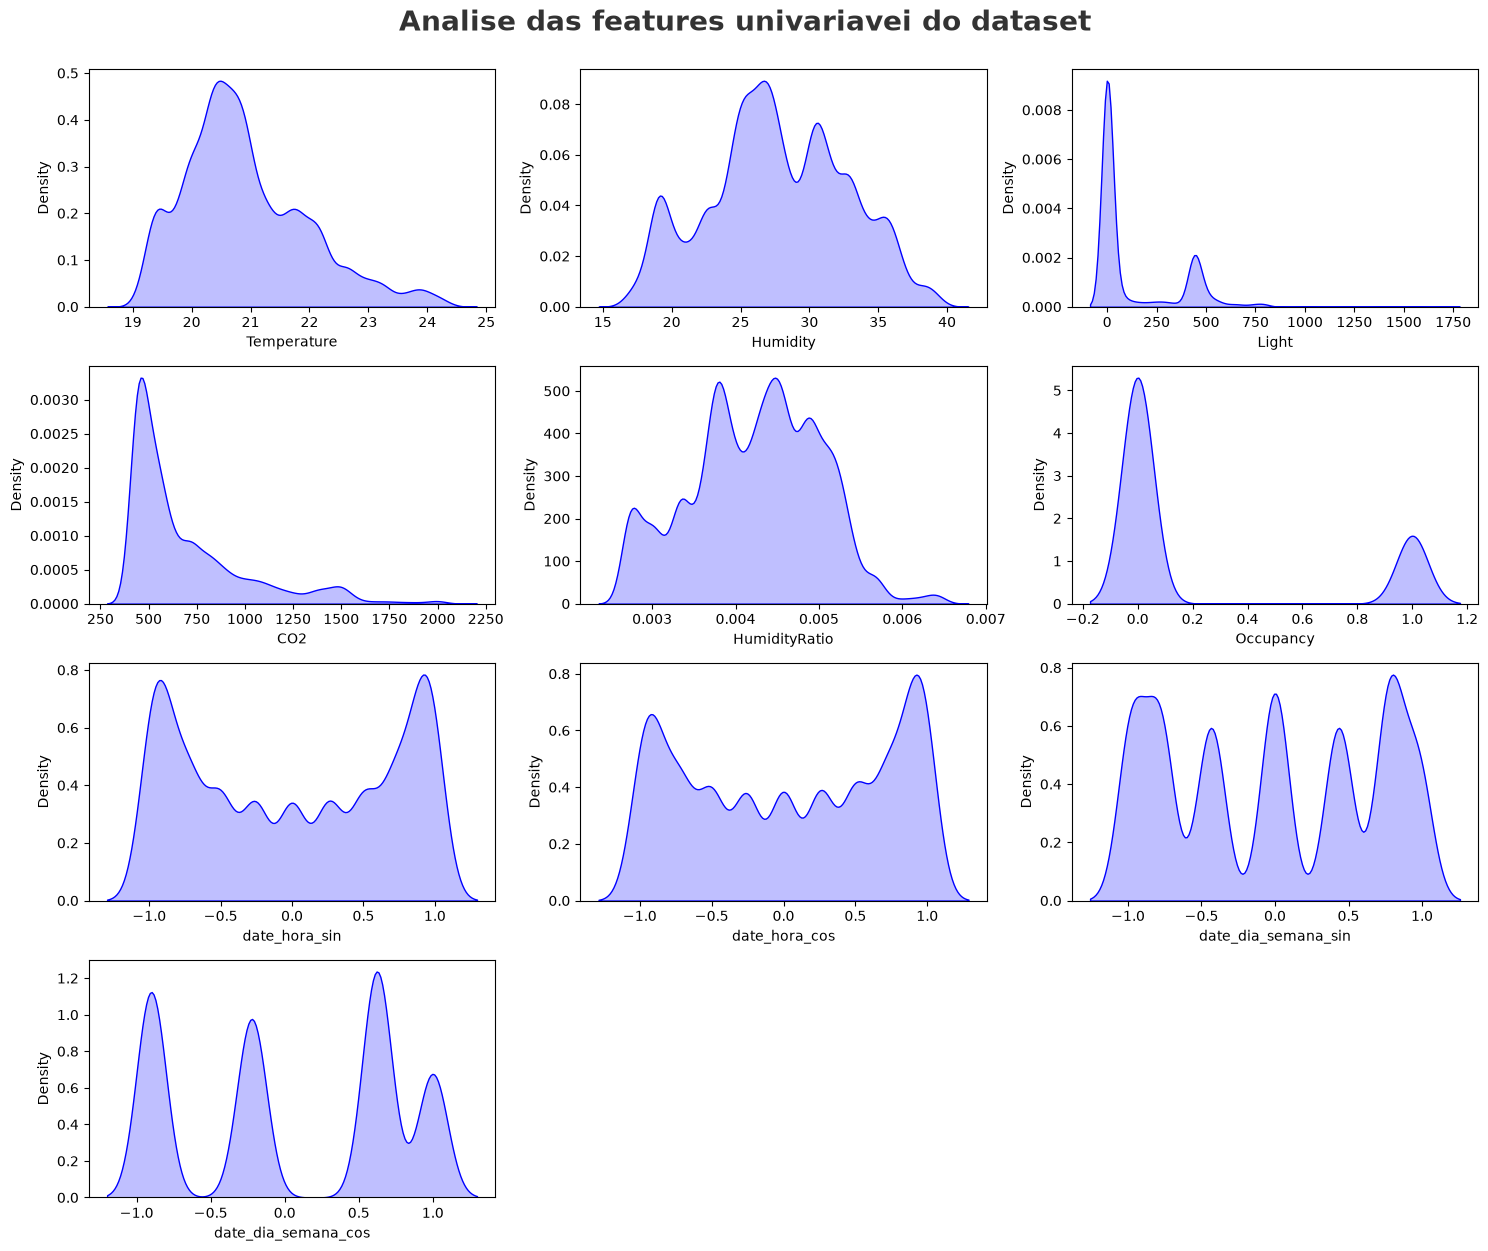

In [53]:

plt.figure(figsize=(15,15))
plt.suptitle("Analise das features univariavei do dataset", fontsize=20, fontweight='bold', alpha=0.8, y = 1.)

for data in datasets:
    plt.figure(figsize=(15,15))
    plt.suptitle("Analise das features univariavei do dataset", fontsize=20, fontweight='bold', alpha=0.8, y = 1.)
    
    for i in range(len(features_numericas)):
        plt.subplot(5,3, i + 1)
        
        sns.kdeplot(x = data[features_numericas[i]], fill=True, color = 'b')
        plt.xlabel(features_numericas[i])
        
    plt.tight_layout() 
    plt.show()

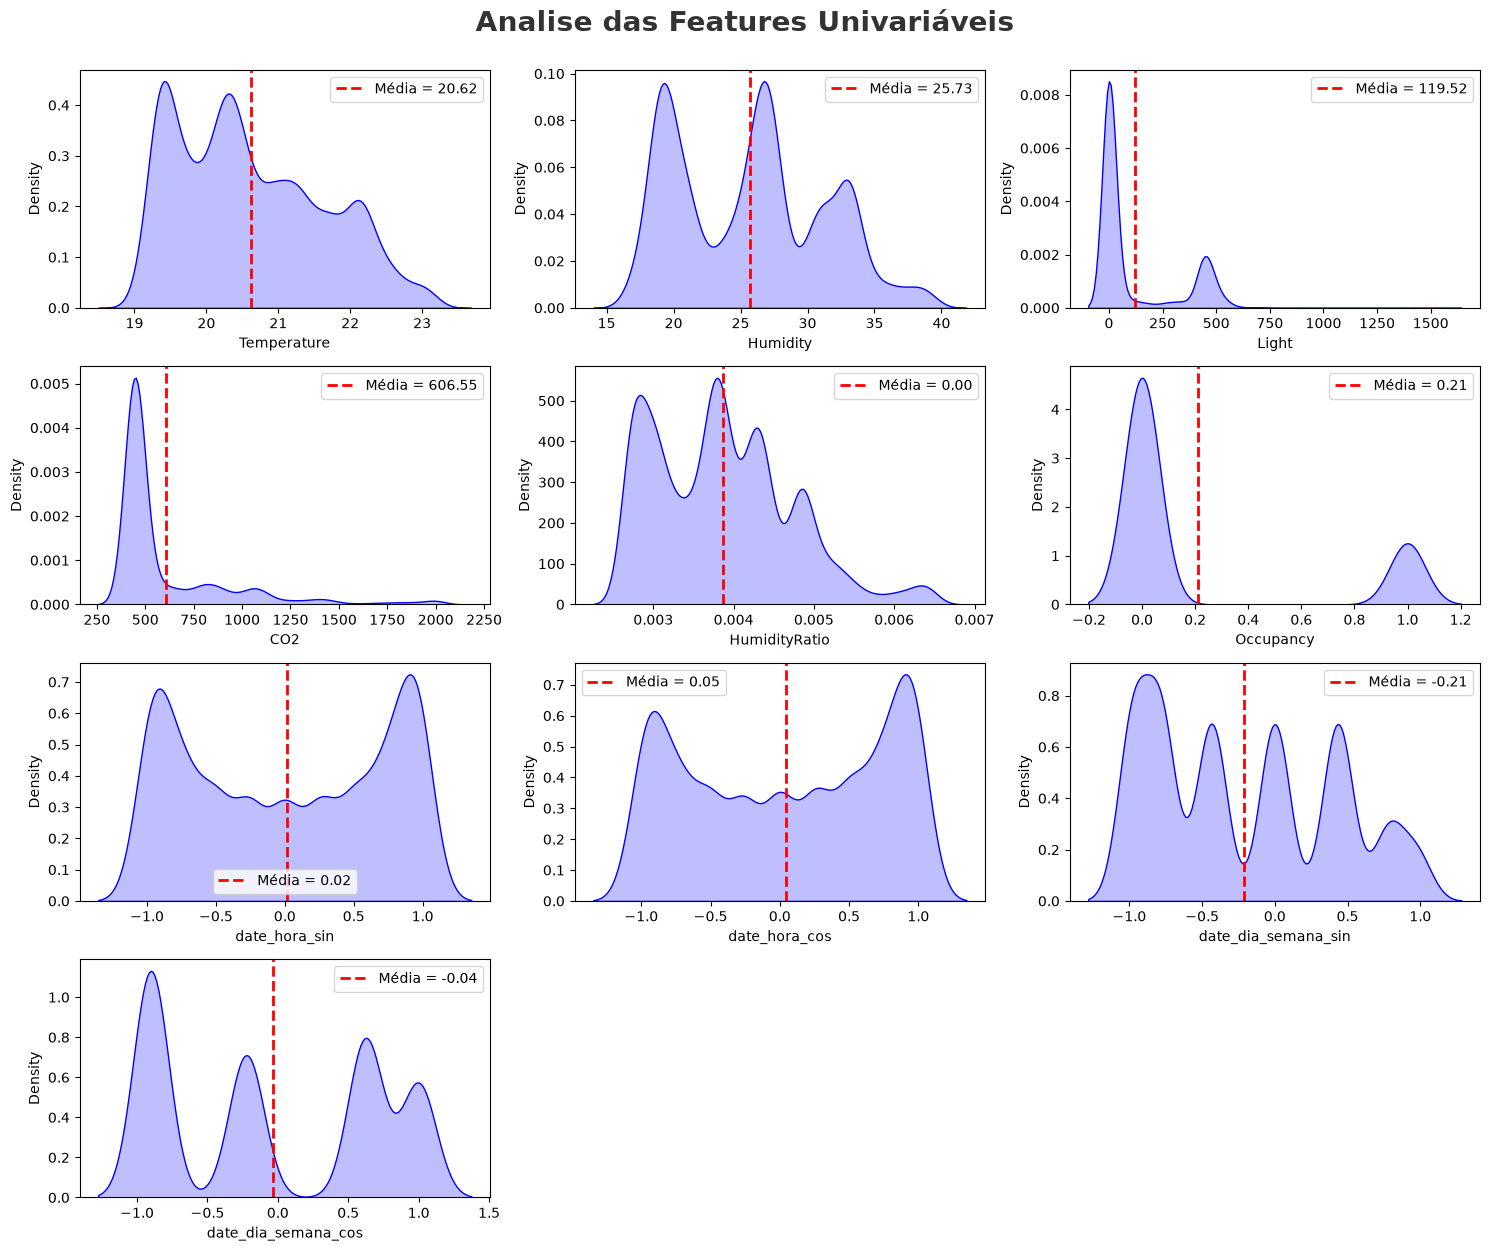

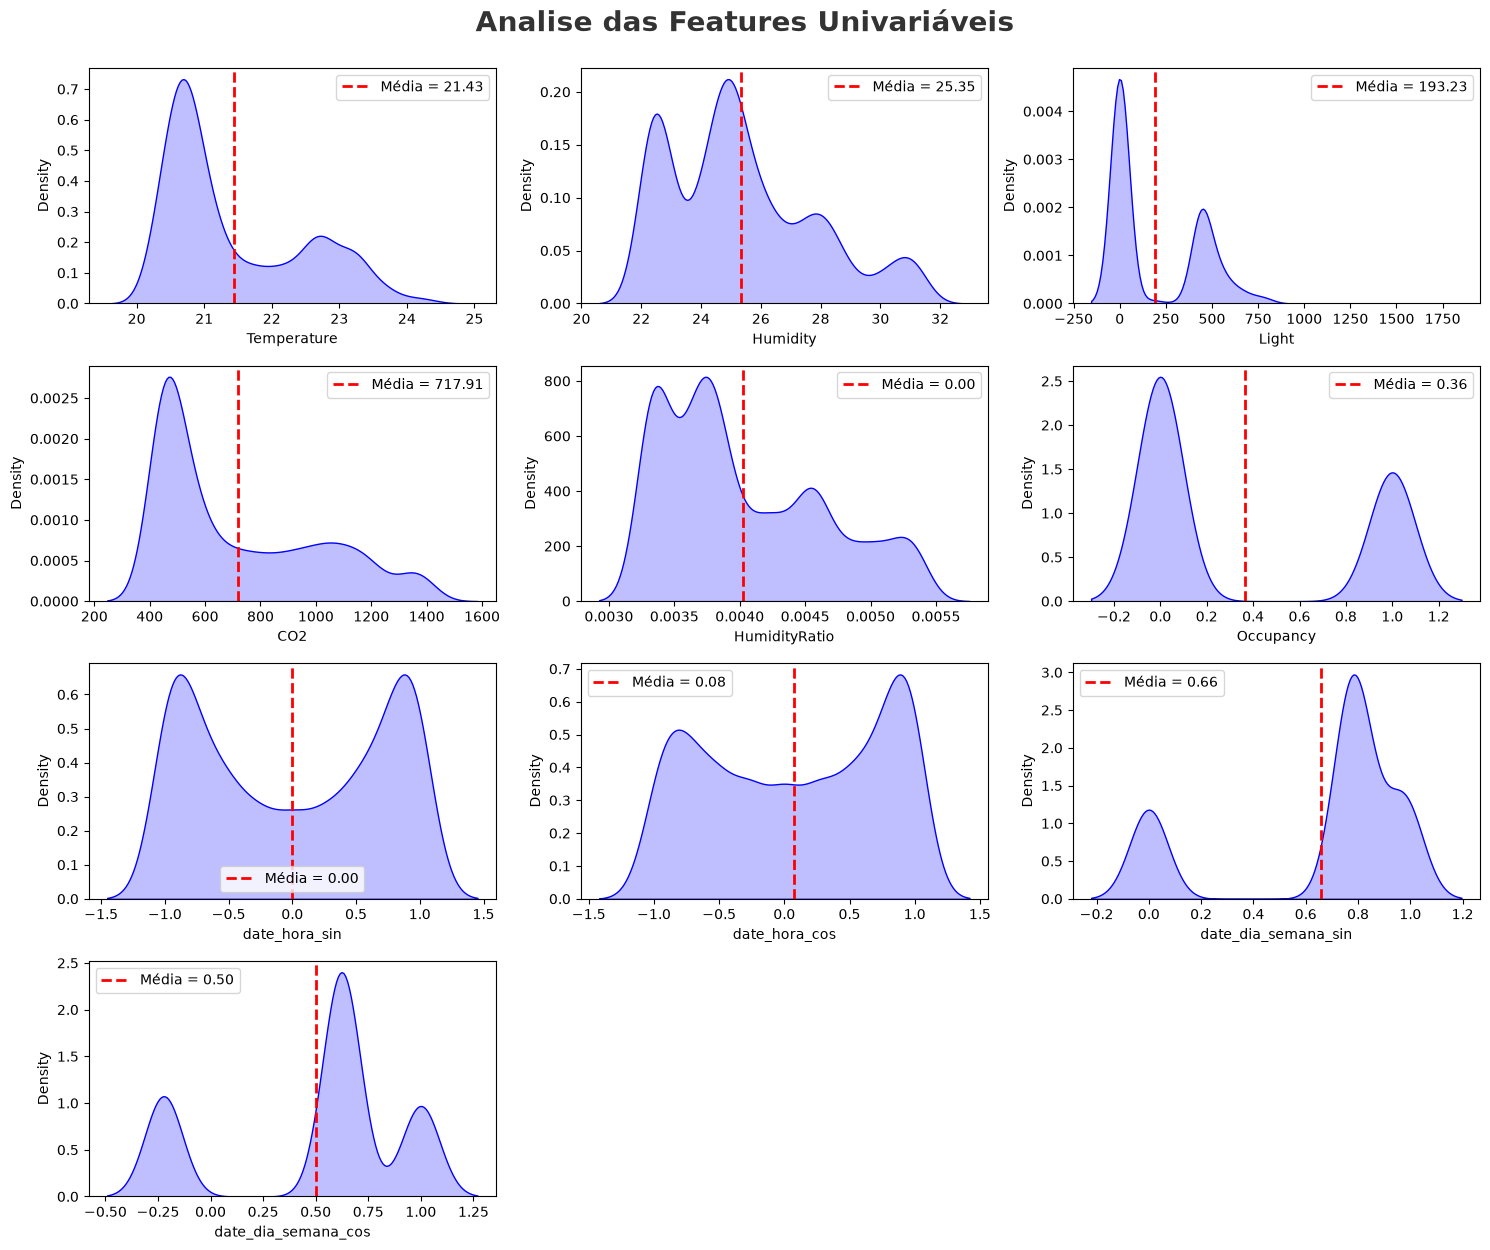

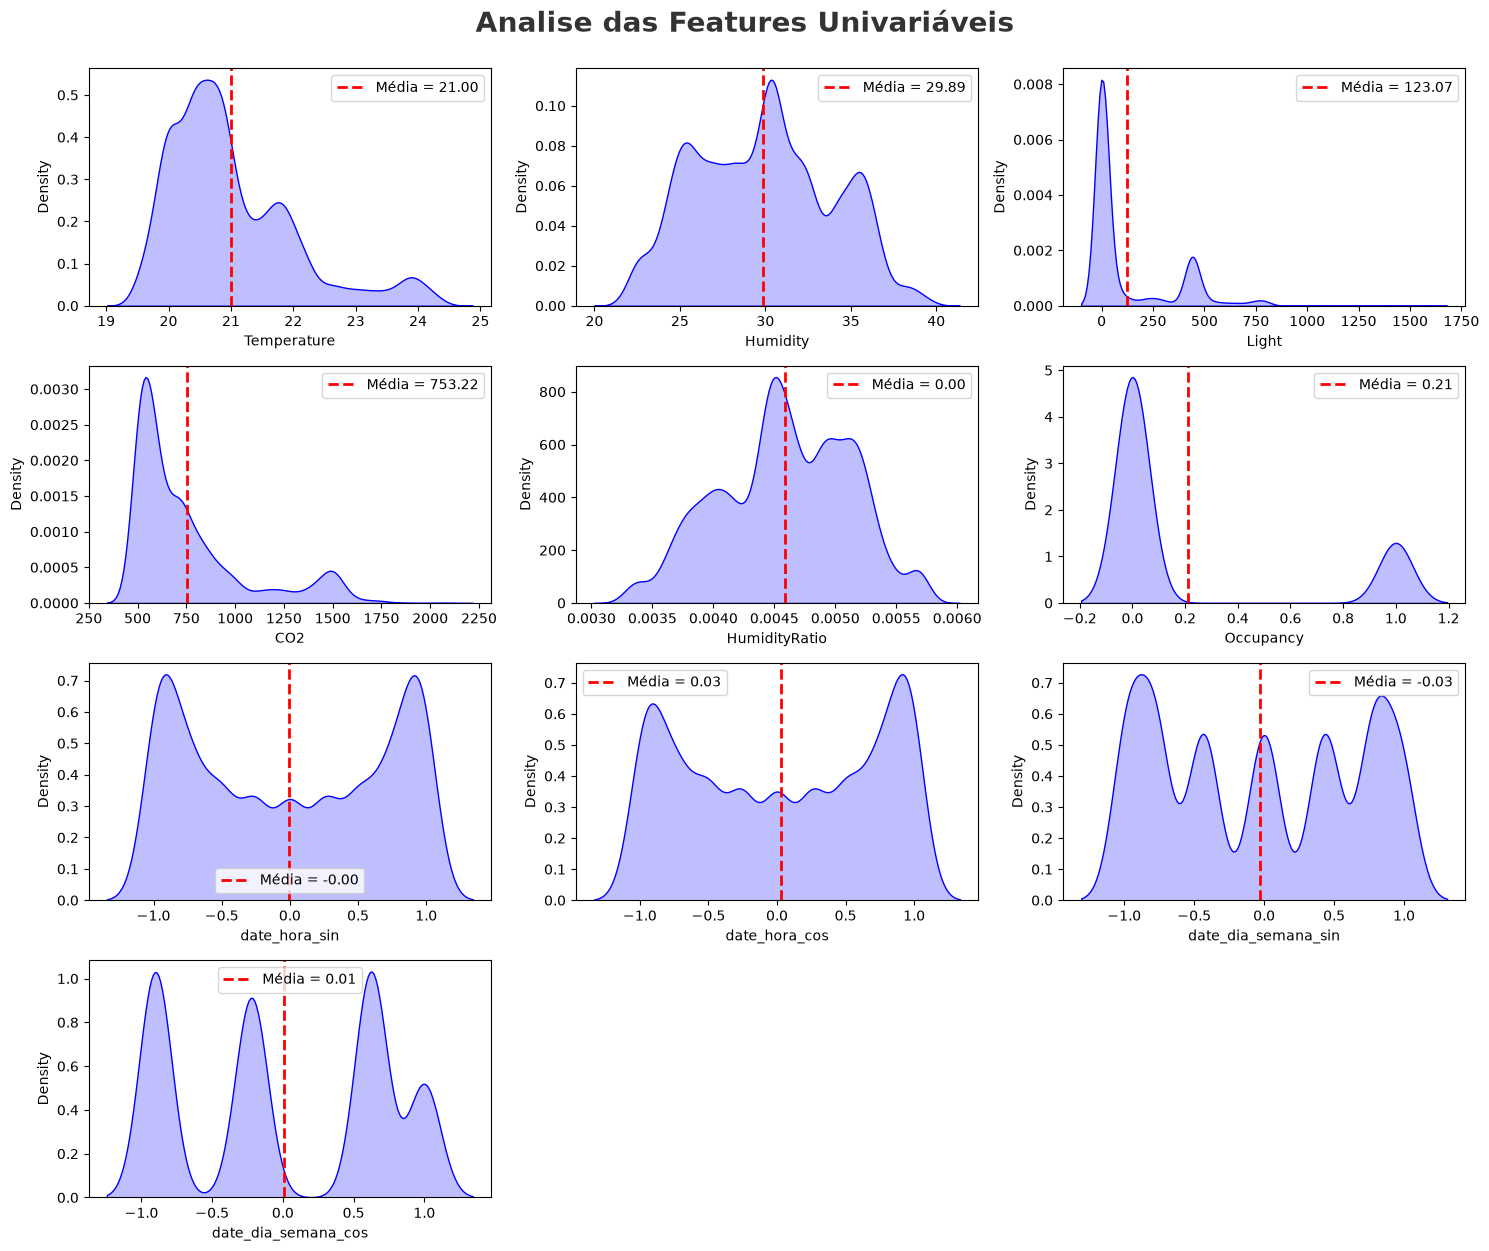

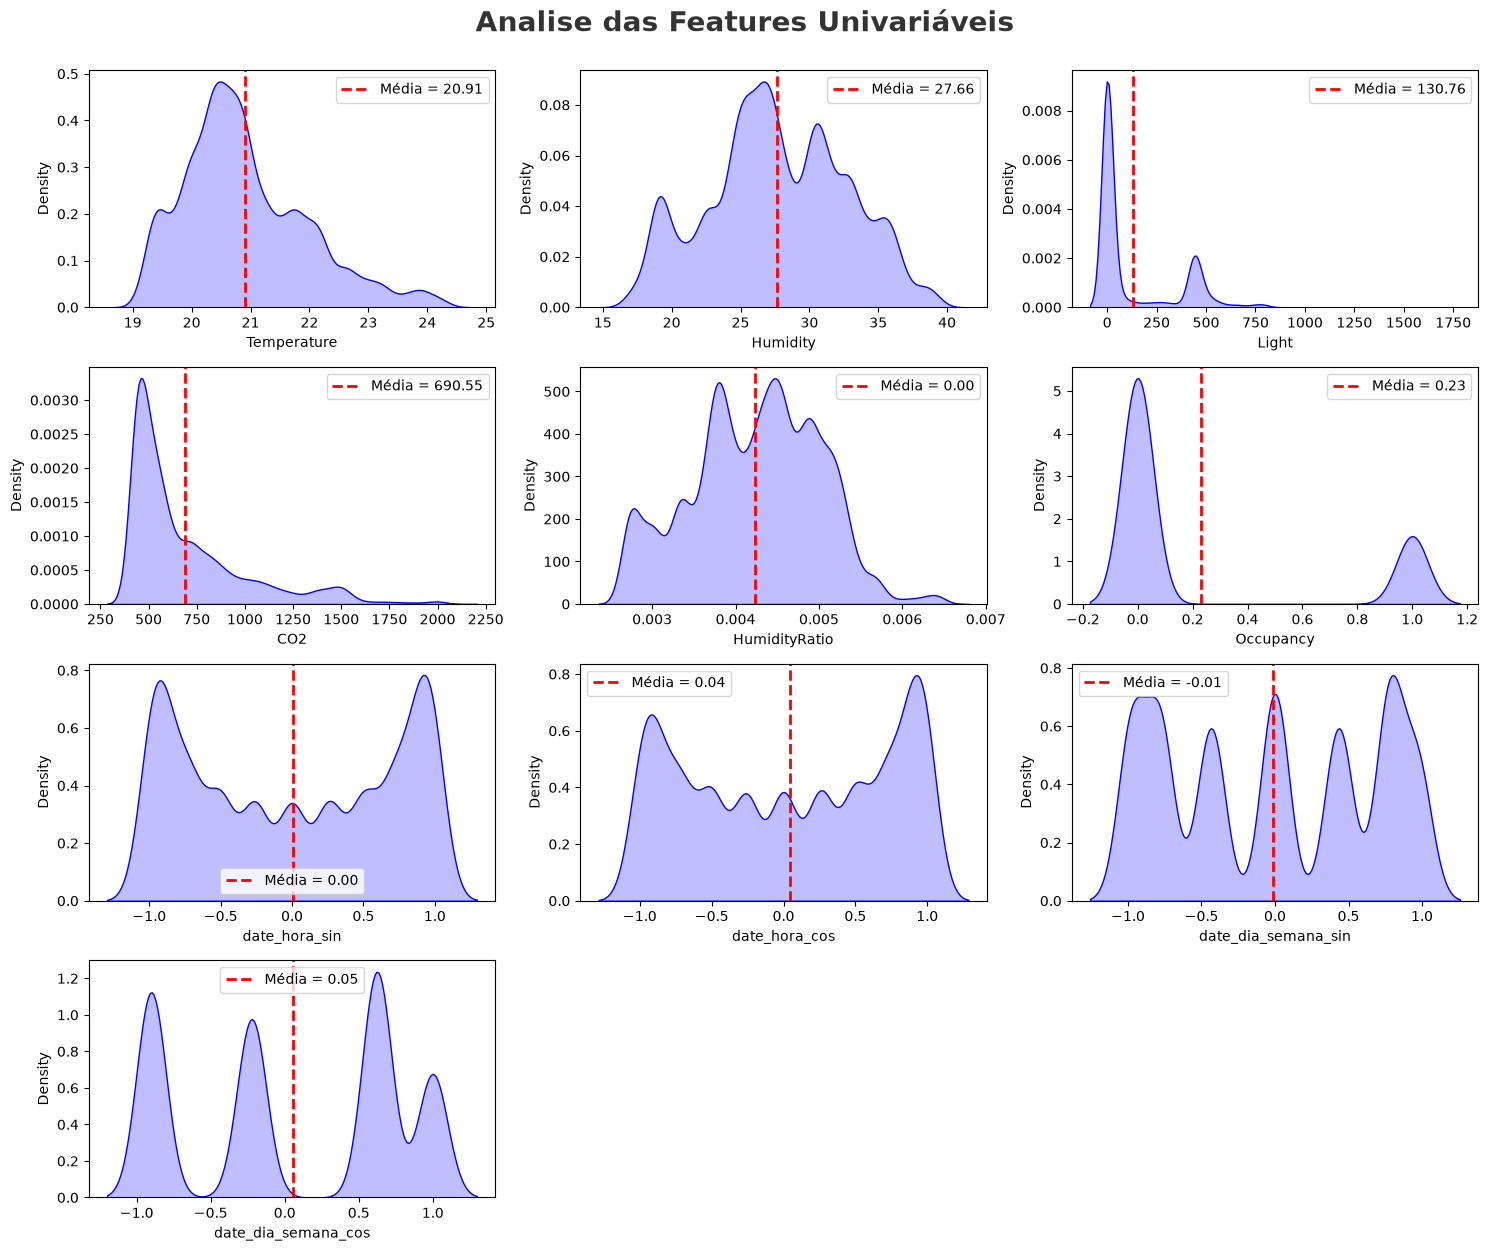

In [54]:
for data in datasets:
    plt.figure(figsize=(15,15))
    plt.suptitle("Analise das Features Univariáveis", fontsize=20, fontweight='bold', alpha=0.8, y = 1.)
    
    for i in range(len(features_numericas)):
        plt.subplot(5,3, i + 1)
        
        media = data[features_numericas[i]].mean()
        plt.axvline(media, color="red", linestyle="--", linewidth=2, label=f"Média = {media:.2f}")
        
        sns.kdeplot(x = data[features_numericas[i]], fill=True, color = 'b')
        plt.xlabel(features_numericas[i])
        
        plt.legend()
        
    plt.tight_layout() 
    plt.show()

# Boxplot variaveis

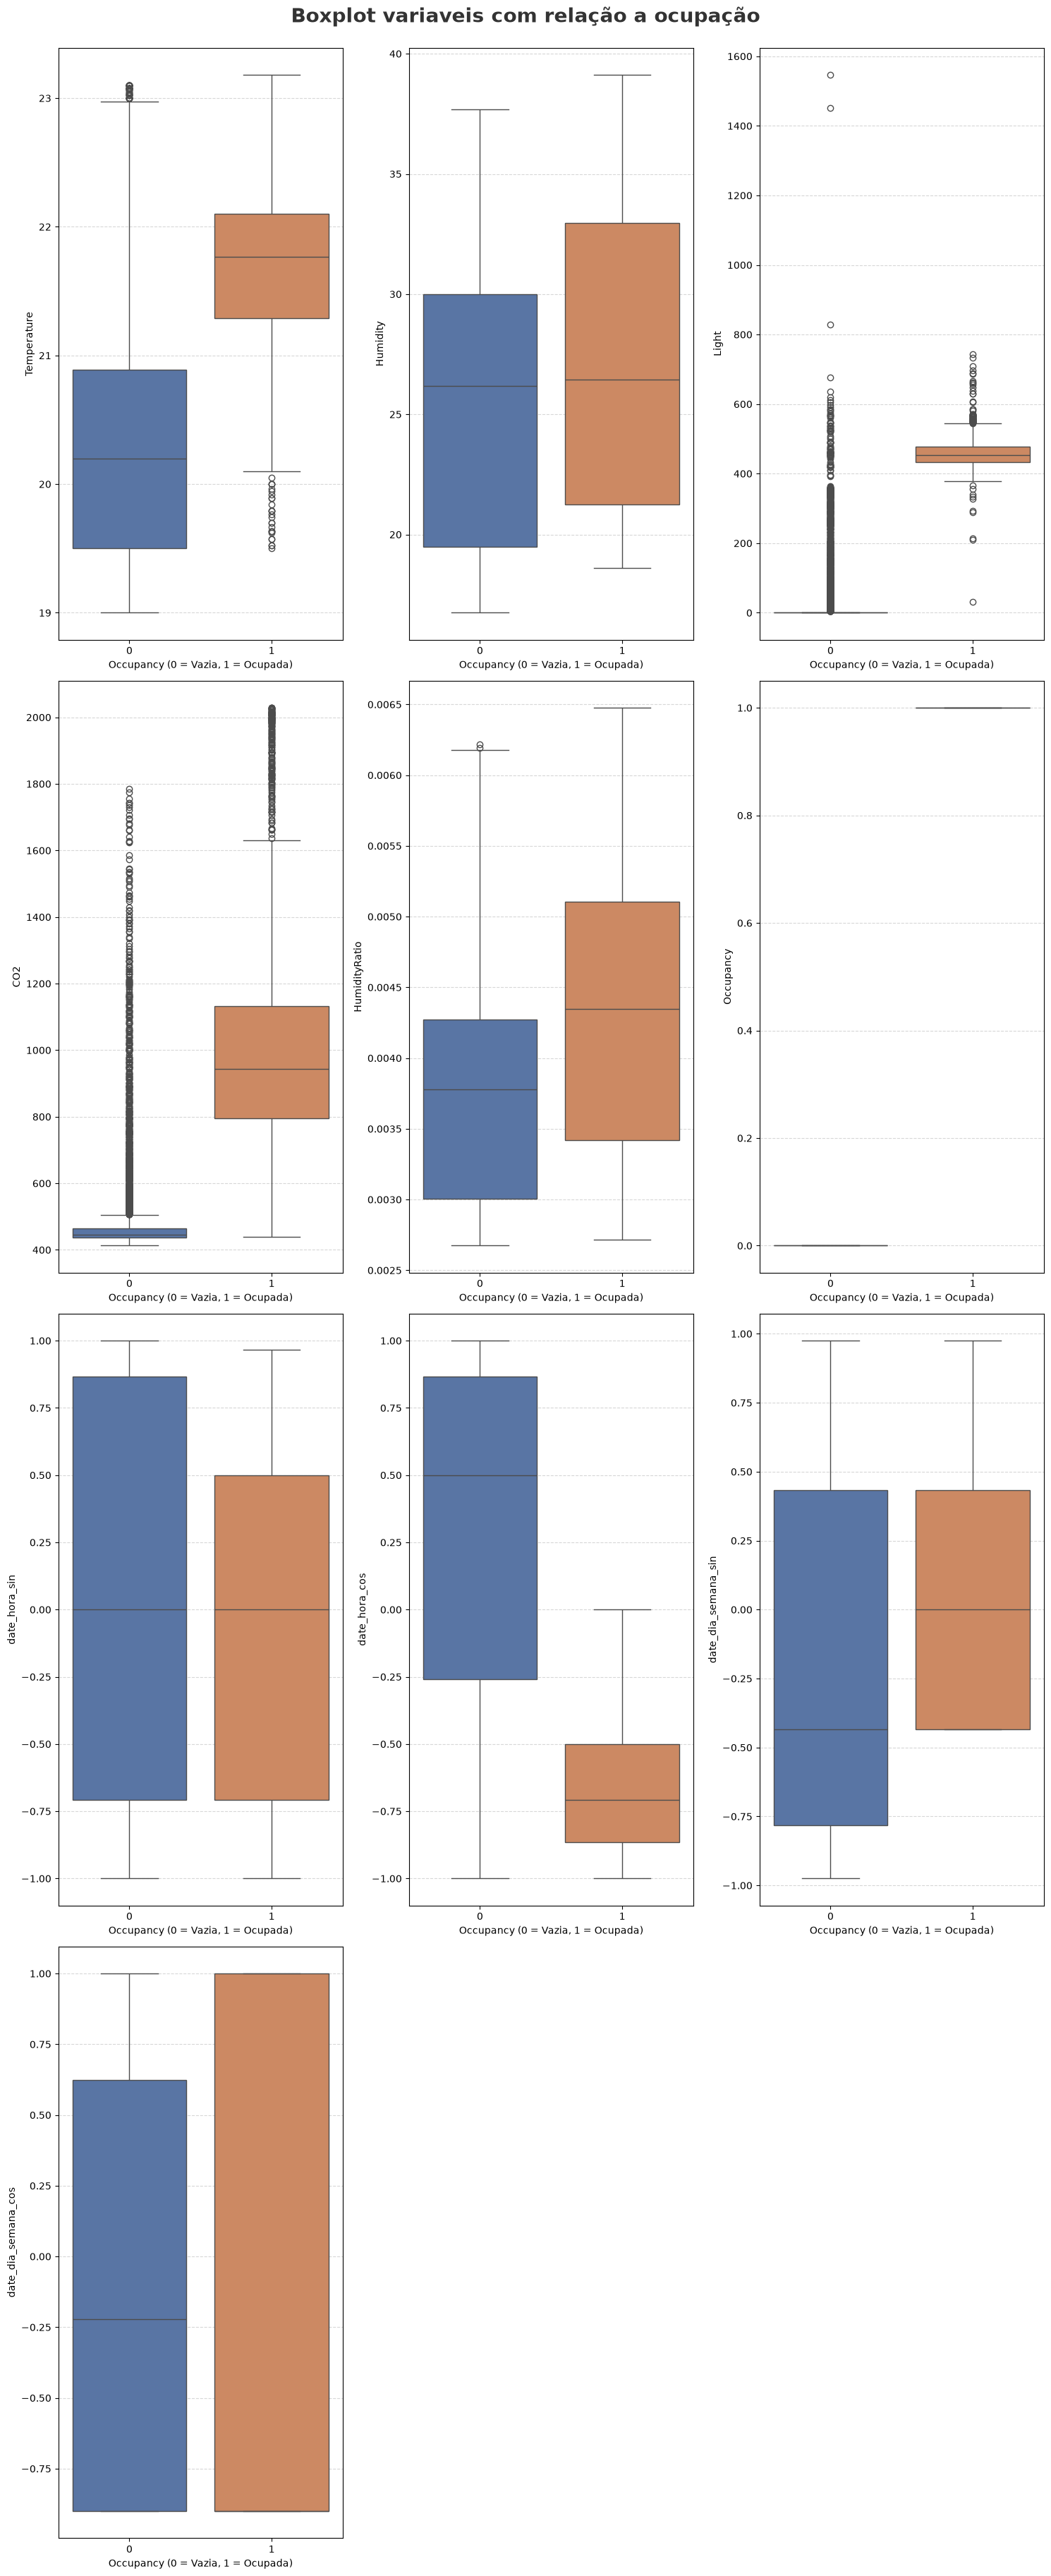

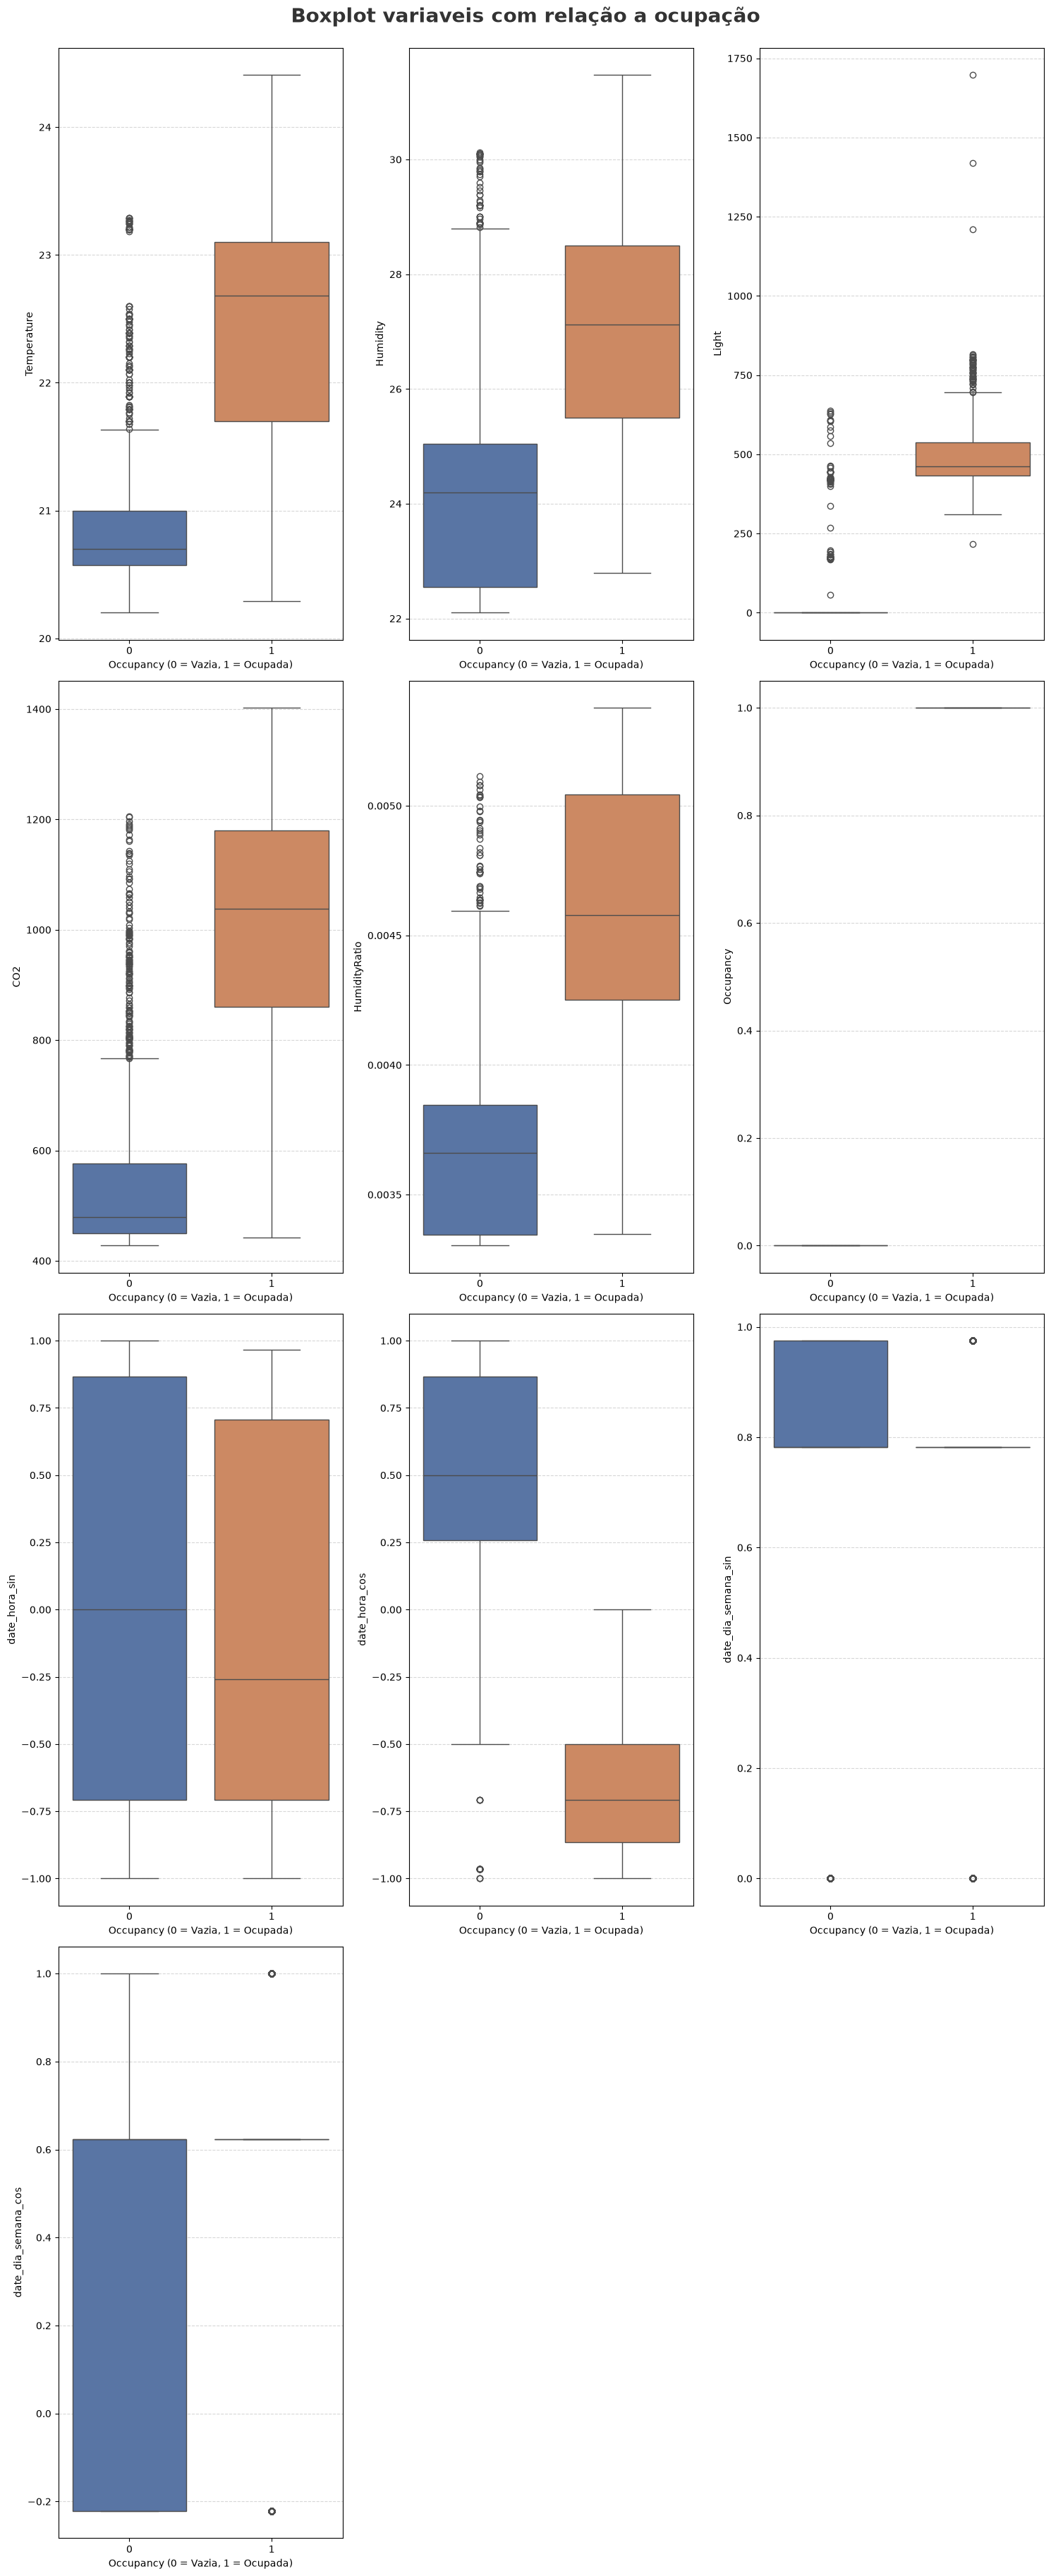

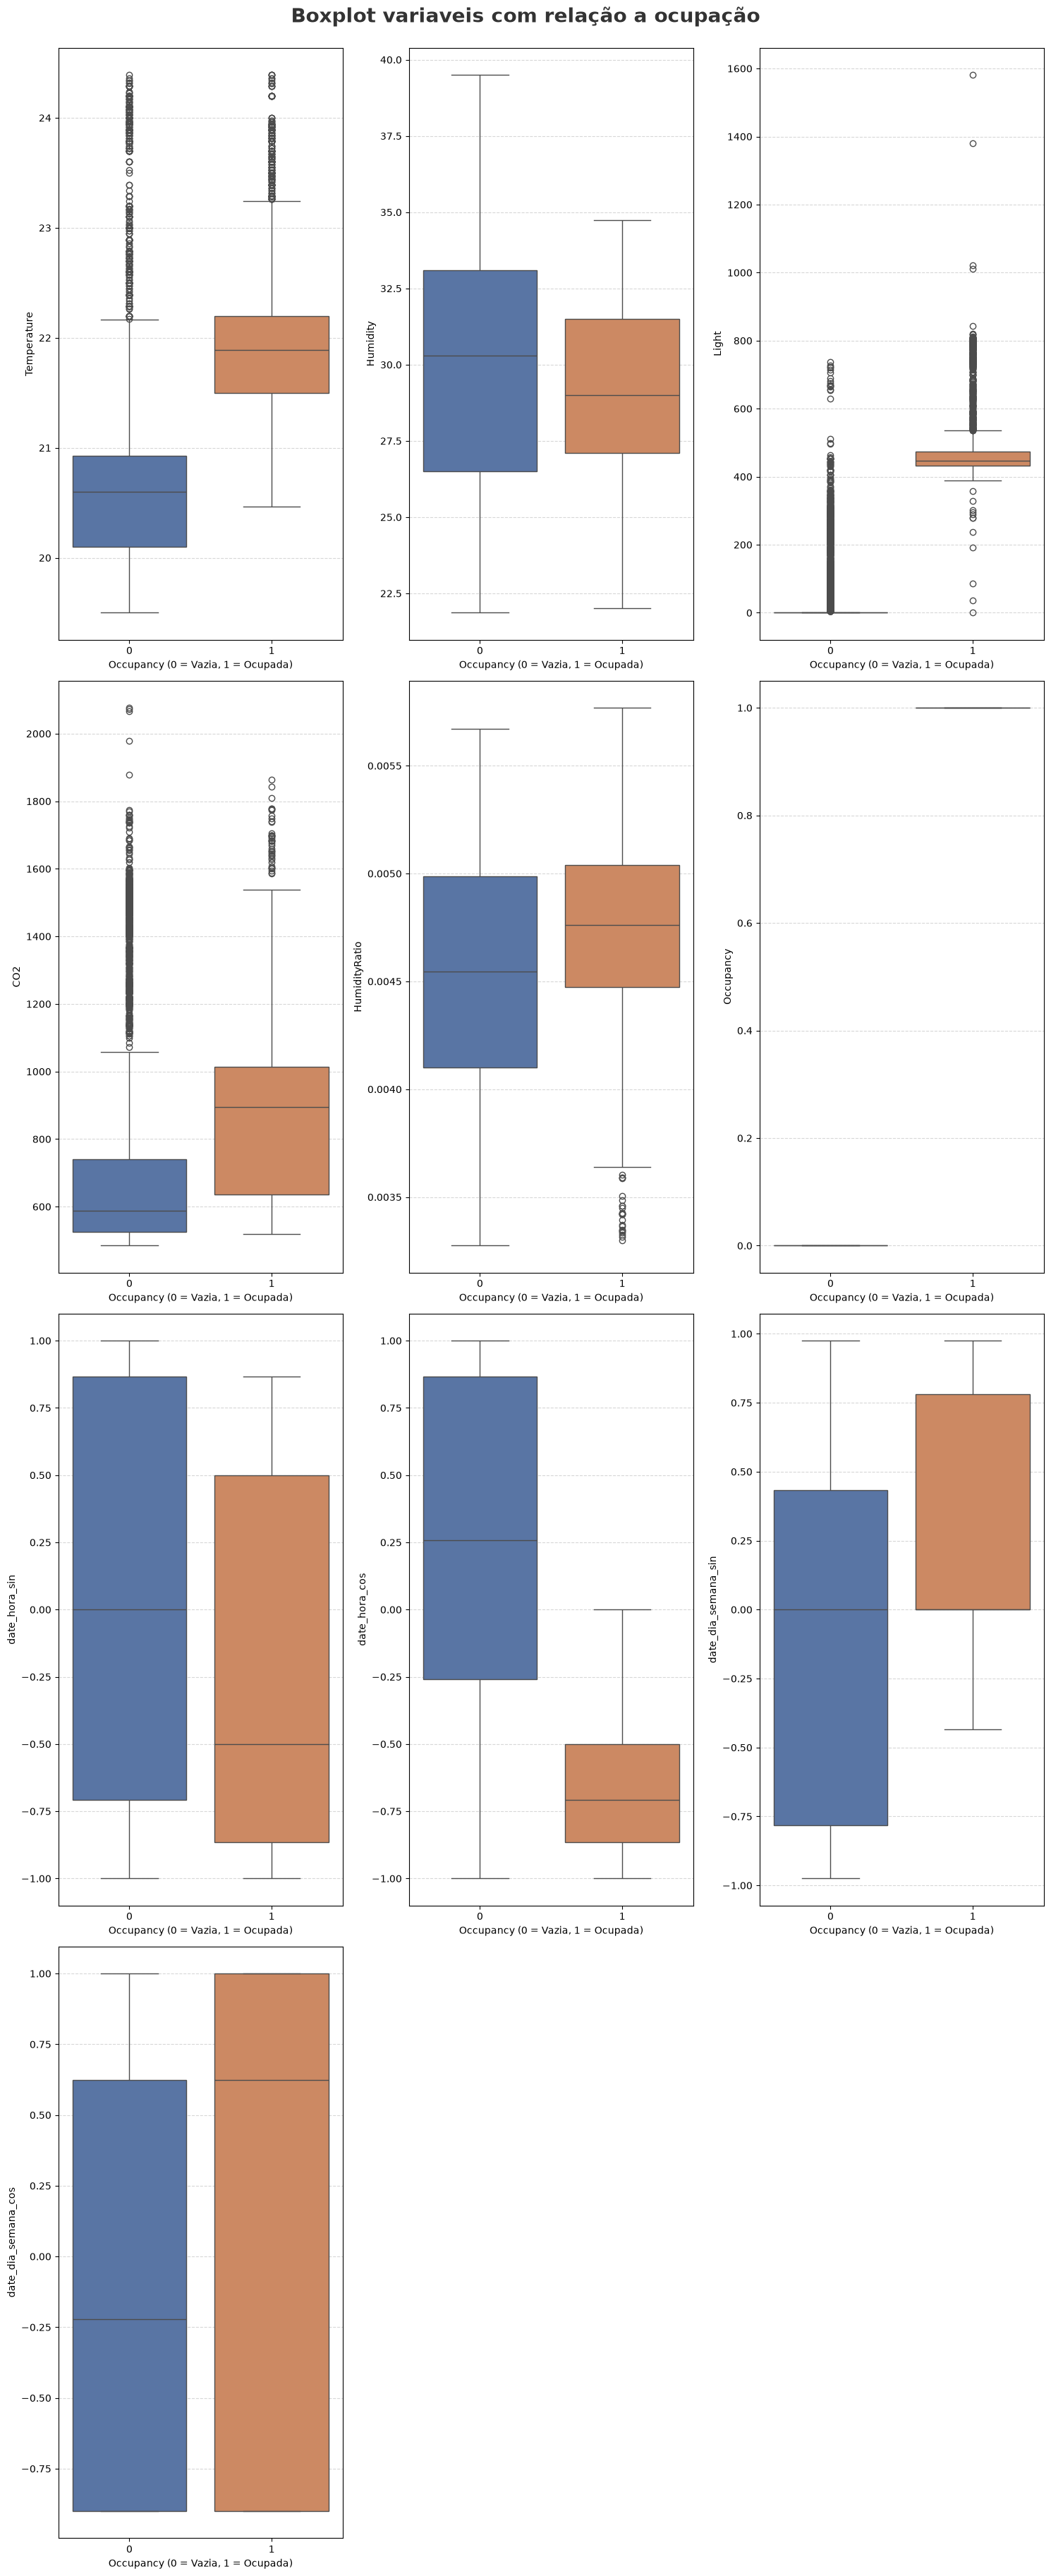

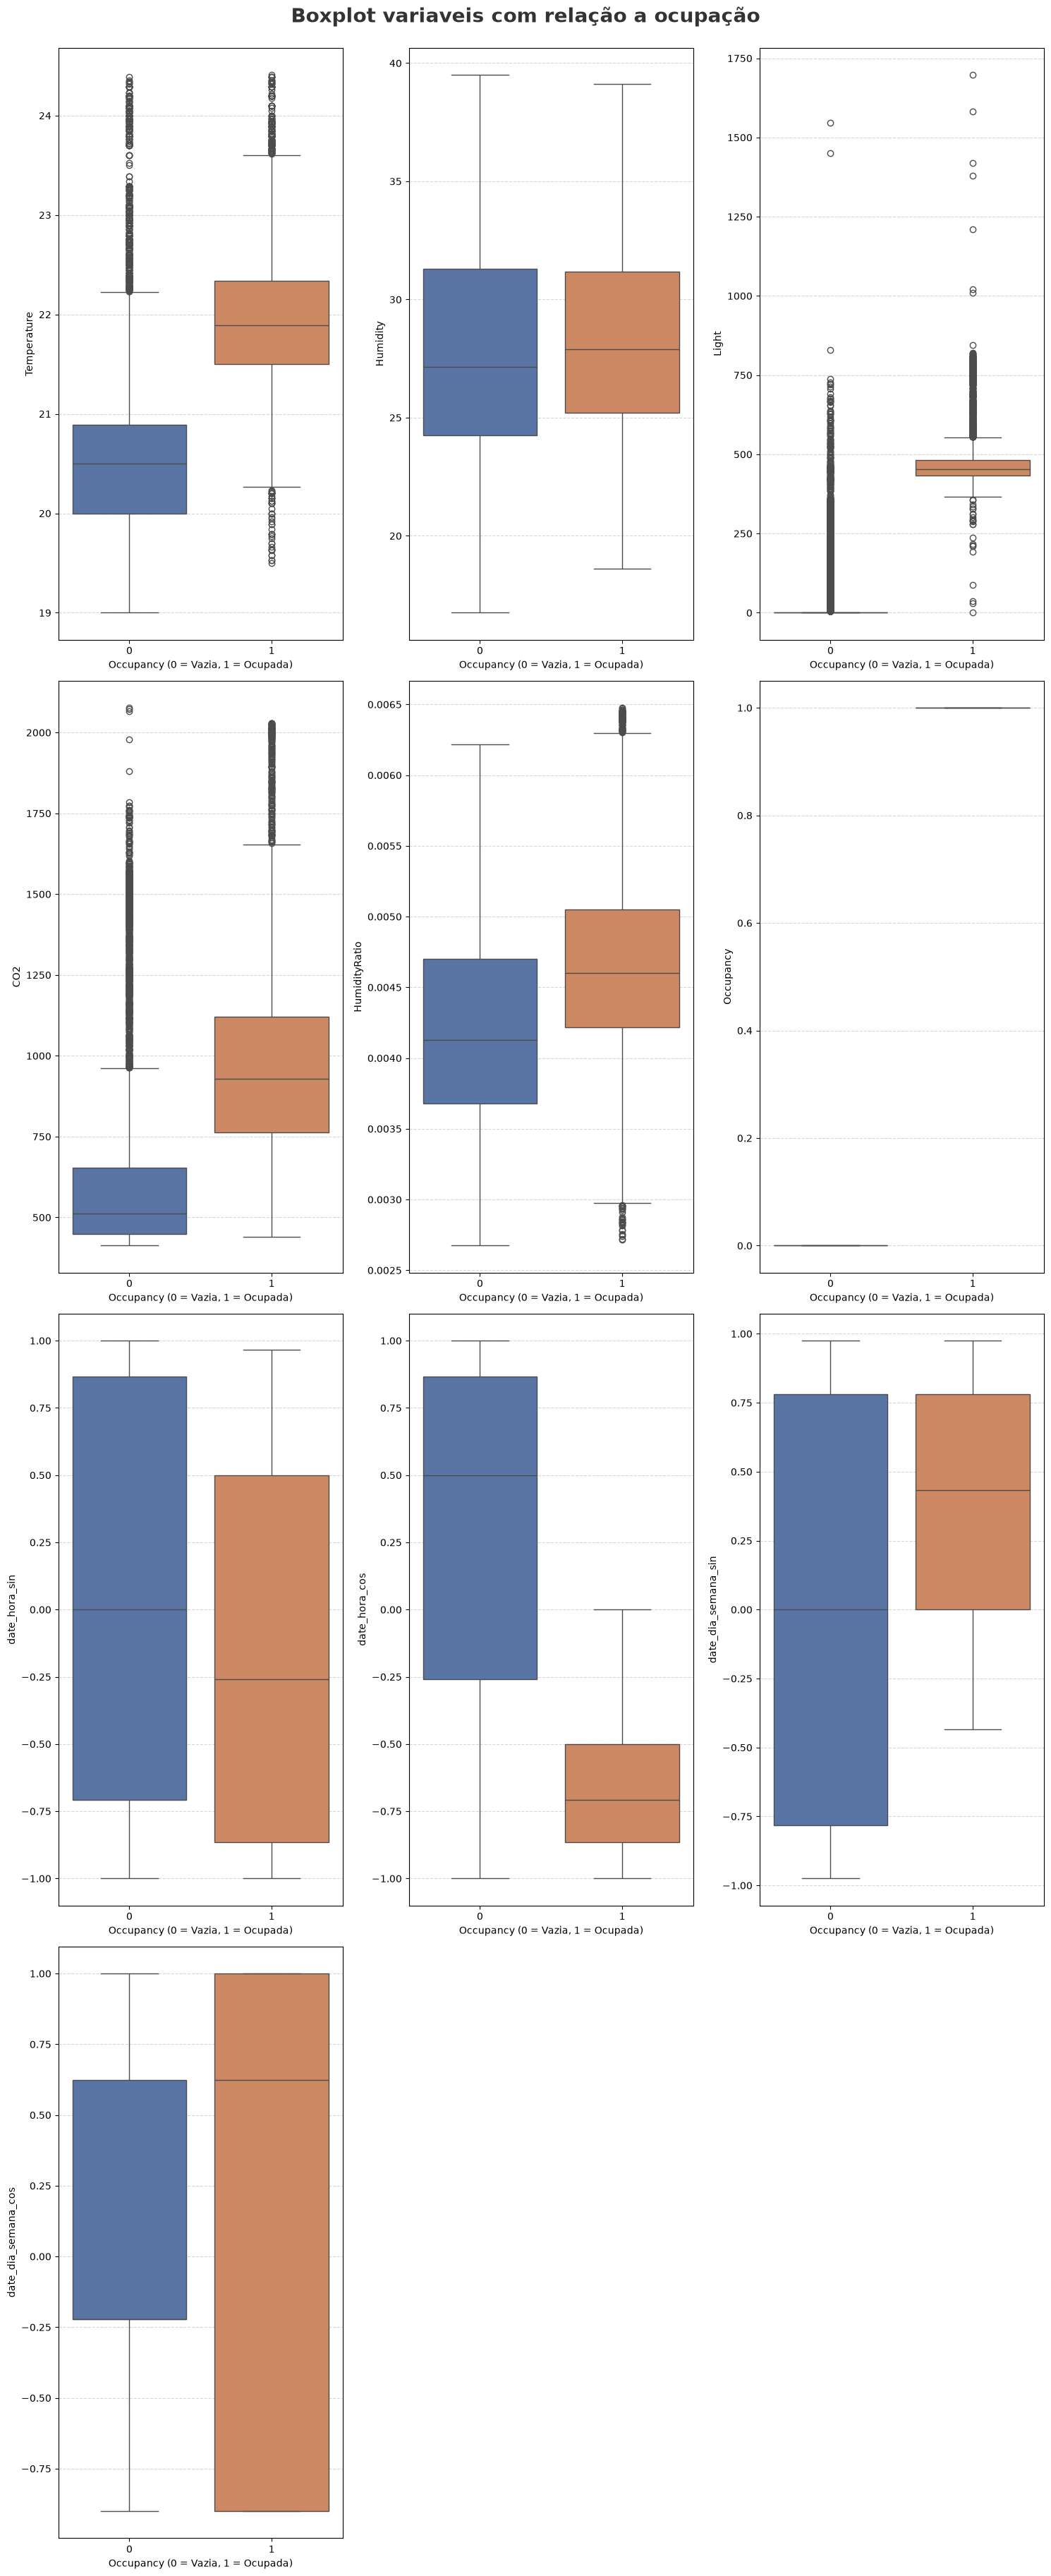

In [85]:
for data in datasets:
    plt.figure(figsize=(15,45))
    plt.suptitle("Boxplot variaveis com relação a ocupação", fontsize=20, fontweight='bold', alpha=0.8, y = 1.)
    
    for i in range(len(features_numericas)):
        plt.subplot(5,3, i + 1)
        
        sns.boxplot(
            data=data,
            x='Occupancy',
            y=features_numericas[i],
            hue='Occupancy',
            palette=['#4C72B0', '#DD8452'],
            legend=False
        )
        
        plt.xlabel('Occupancy (0 = Vazia, 1 = Ocupada)')
        plt.grid(axis='y', linestyle='--', alpha=0.5)
        
    plt.tight_layout() 
    plt.show()

# Matriz Correlação Variáveis

In [55]:
def matriz_corr(df, nome=""):
    matriz        = df.corr()
    matriz_sem_date = df.drop(['date'], axis=1).corr()

    plt.figure(figsize=(10, 8))
    sns.heatmap(matriz, cmap='GnBu', annot=True)
    plt.title(f"Matriz de correlação — {nome}",
              fontsize=14, fontweight="bold")
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10, 8))
    sns.heatmap(matriz_sem_date, cmap='GnBu', annot=True)
    plt.title(f"Matriz de correlação — {nome} (sem date)",
              fontsize=14, fontweight="bold")
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

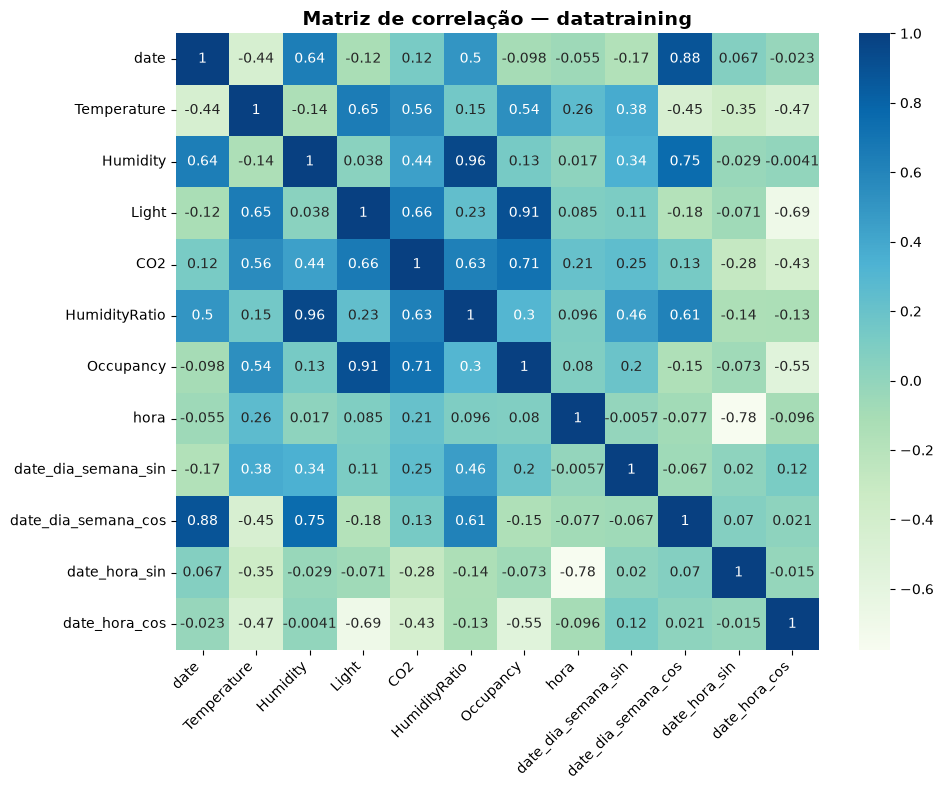

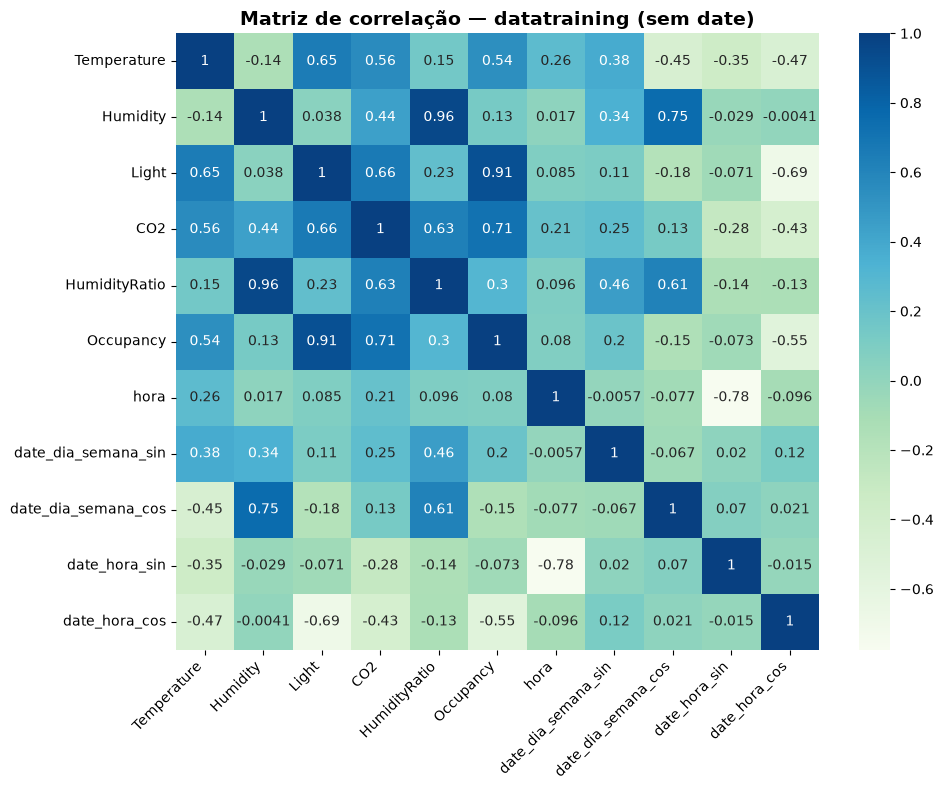

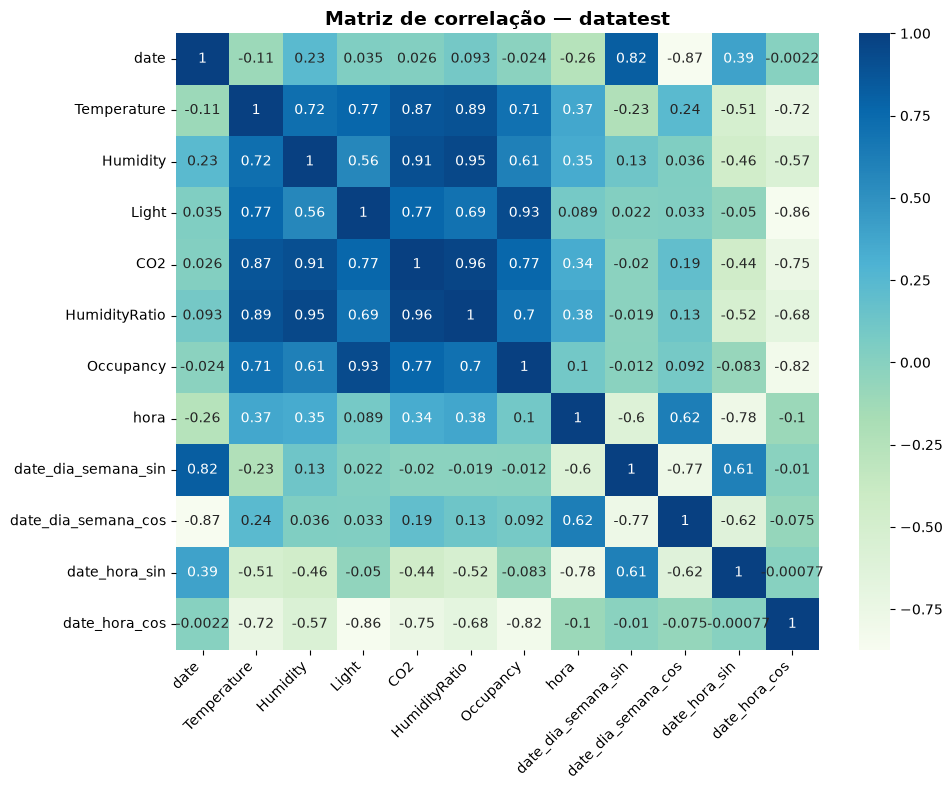

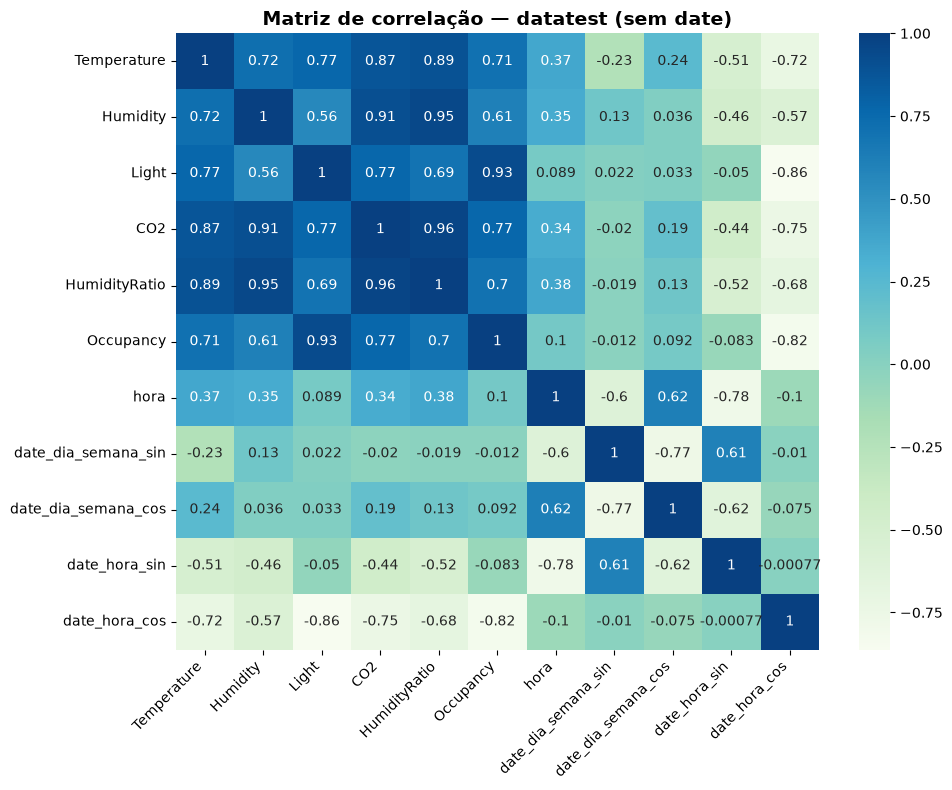

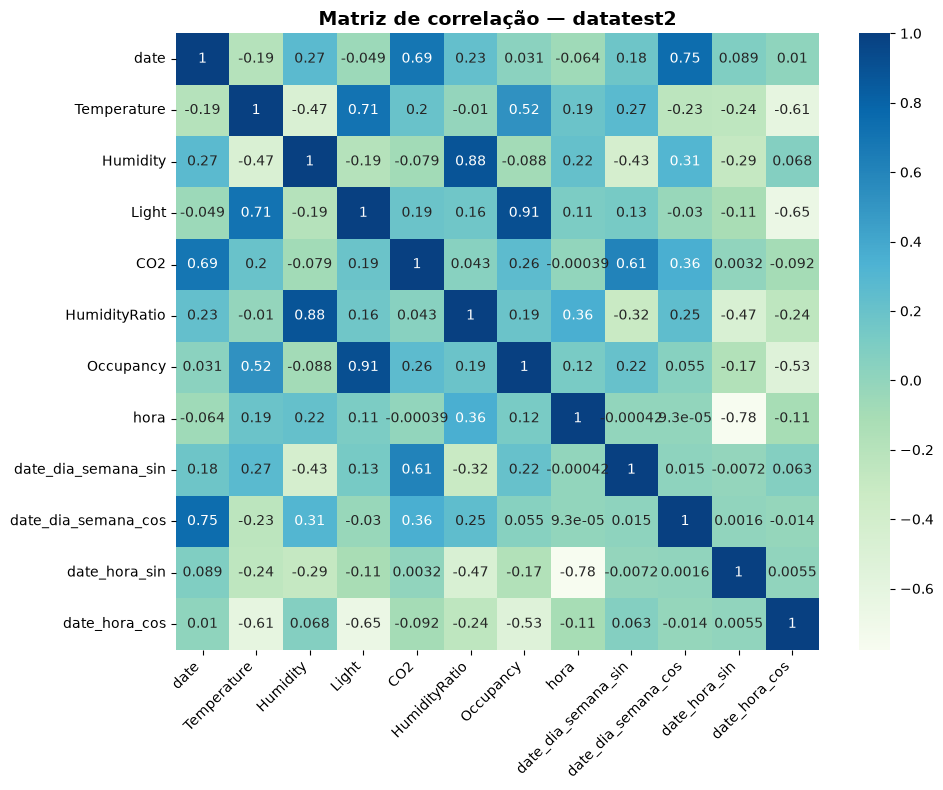

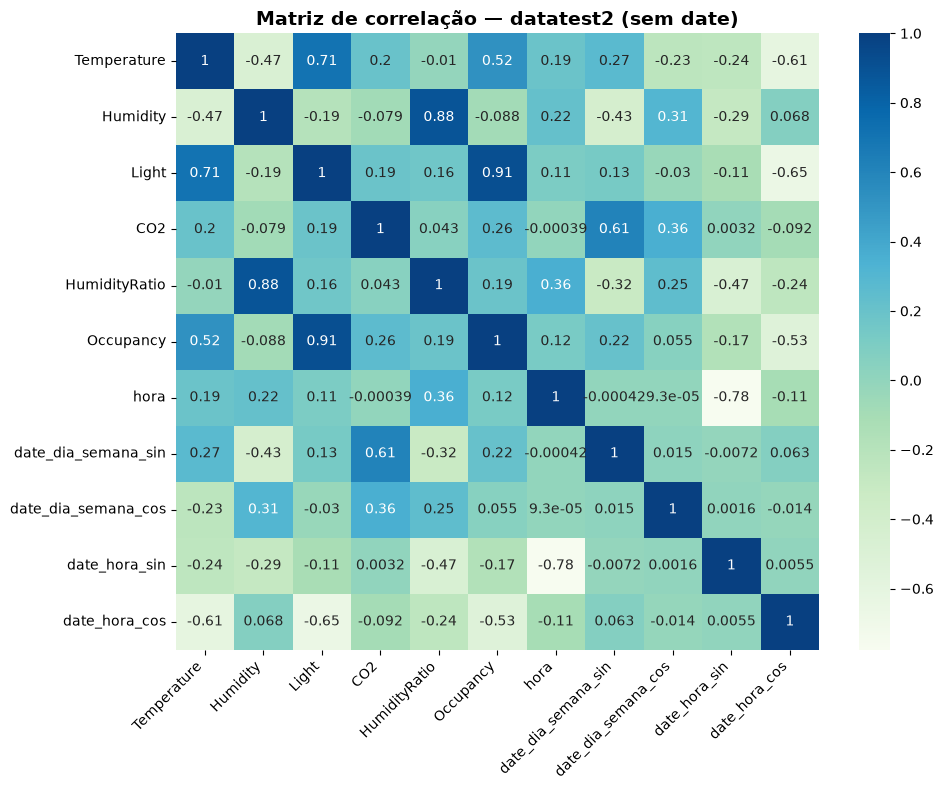

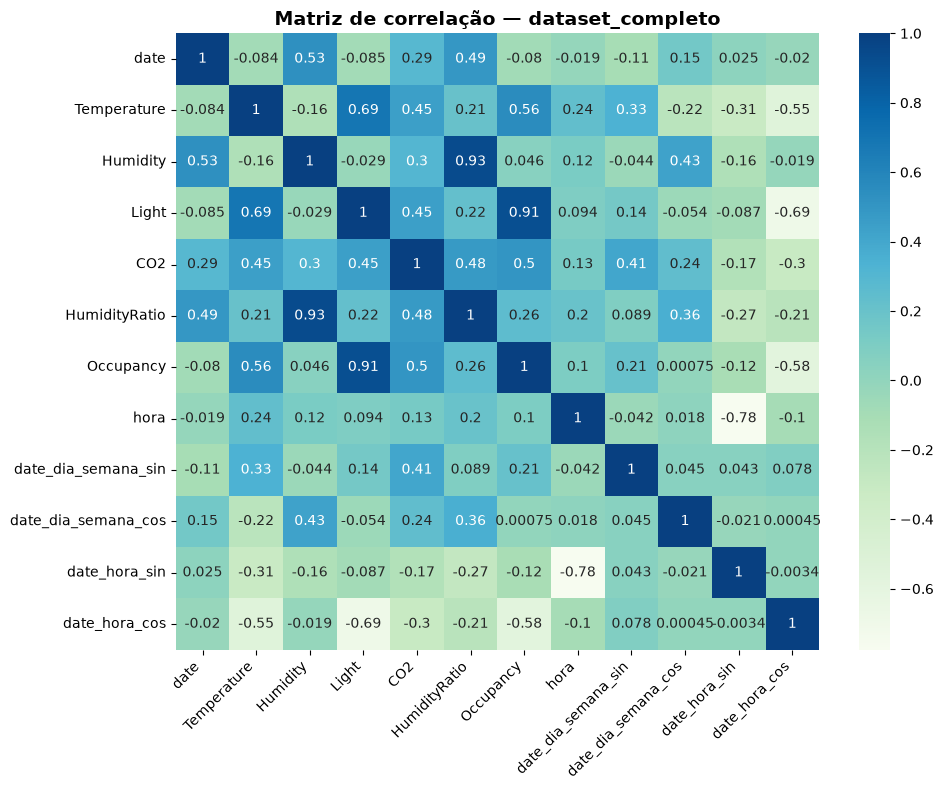

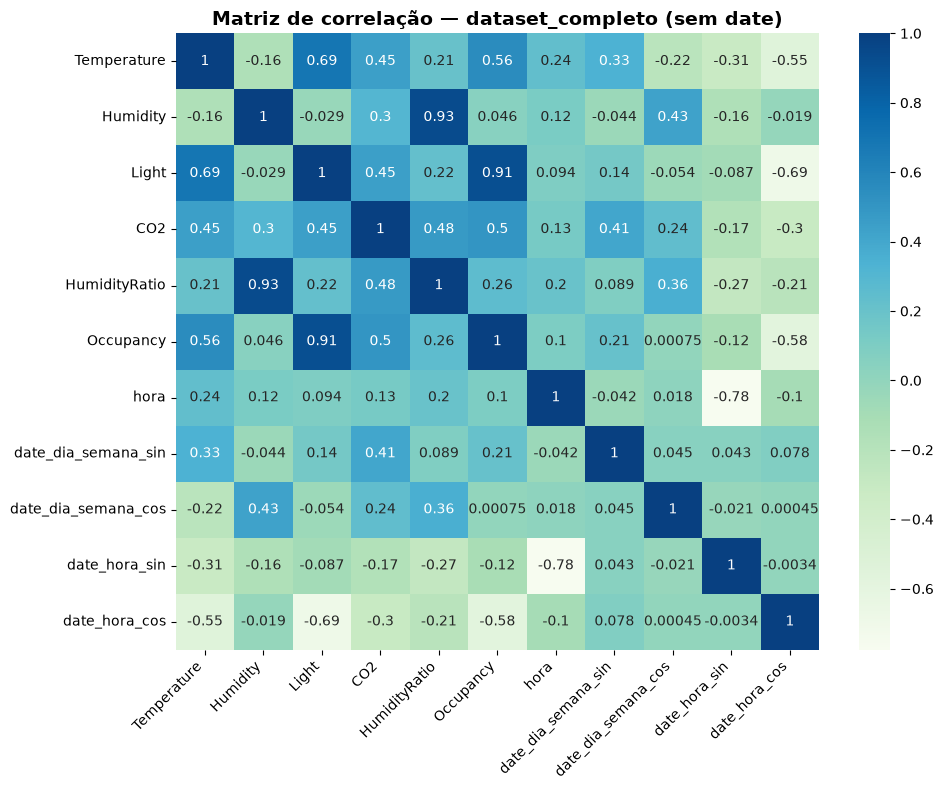

In [56]:
matriz_corr(datatraining, "datatraining")
matriz_corr(datatest, "datatest")
matriz_corr(datatest2, "datatest2")
matriz_corr(dataset_completo, "dataset_completo")

# Como é a distribuição de cada variavel com relação ao tempo

In [81]:
def plot_hora(dataset, intervalo = 1):
    df = dataset.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date")

    for feature in features_numericas:
        ax = df.plot(x="date", y=feature, figsize=(20, 5), legend=False)
        ax.set_facecolor("#ebebeb")
        ax.grid(True, color="white", linewidth=1)
        ax.xaxis.set_major_locator(mdates.HourLocator(interval=intervalo))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
        ax.set_ylabel(feature)
        plt.xticks(rotation=90)
        plt.tight_layout()
        plt.show()

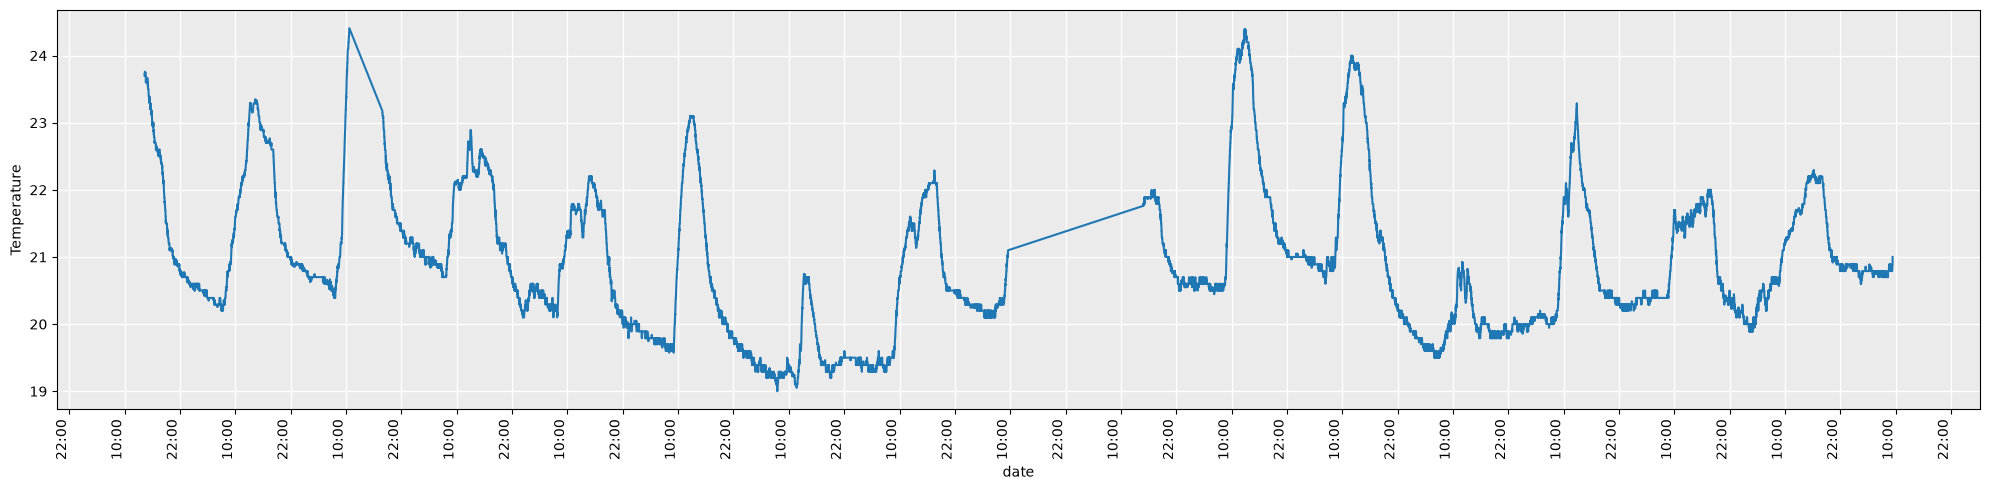

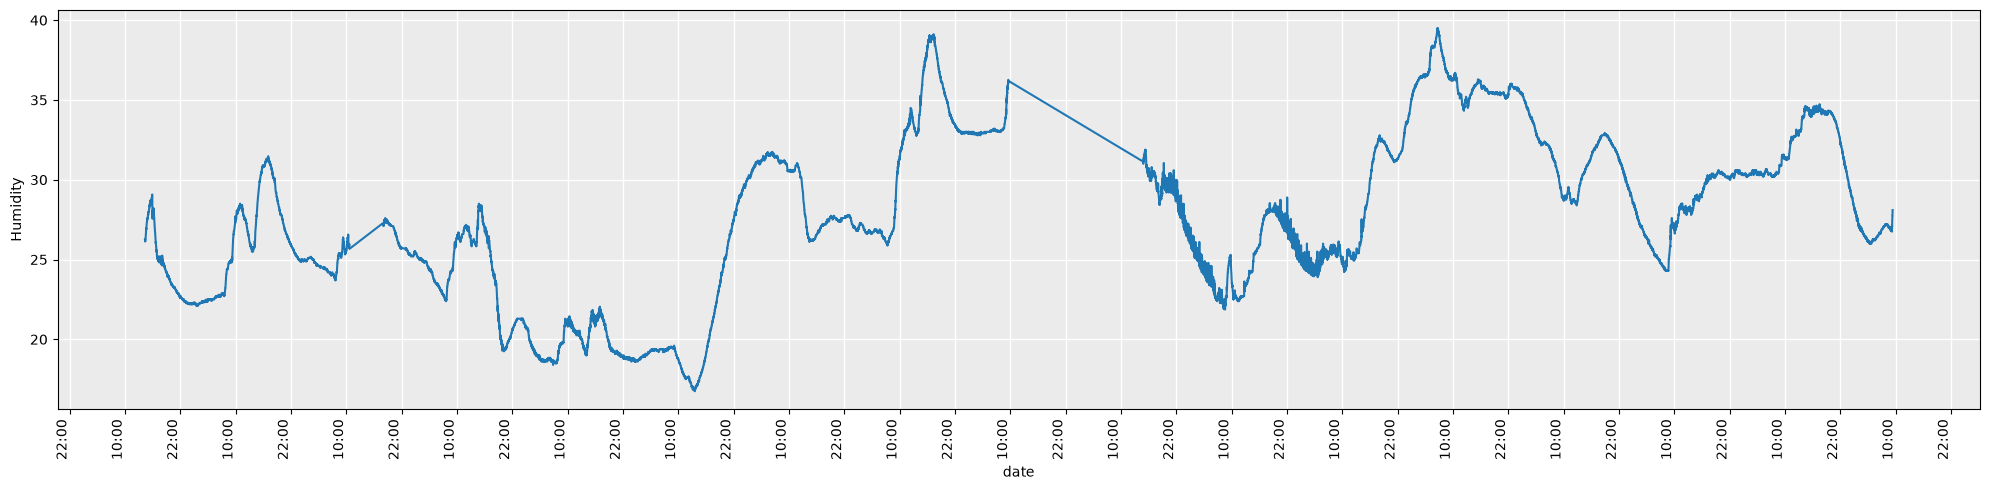

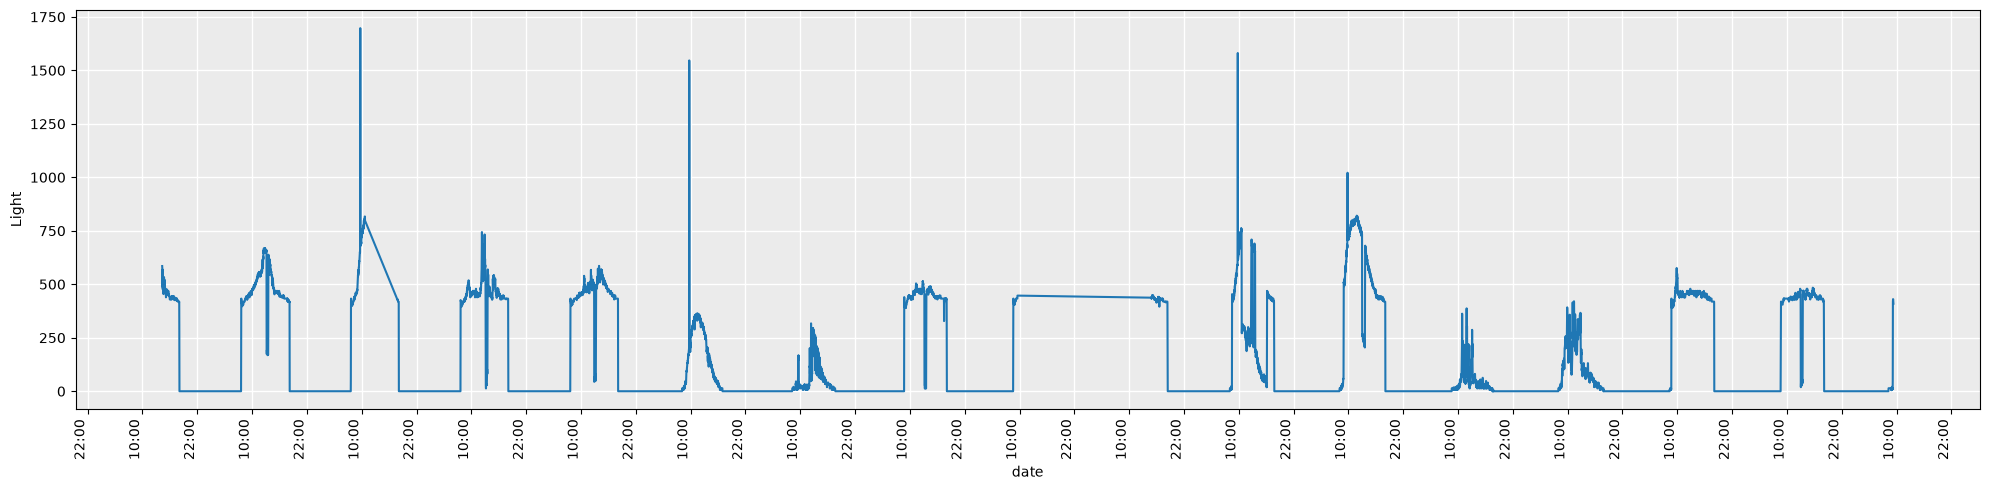

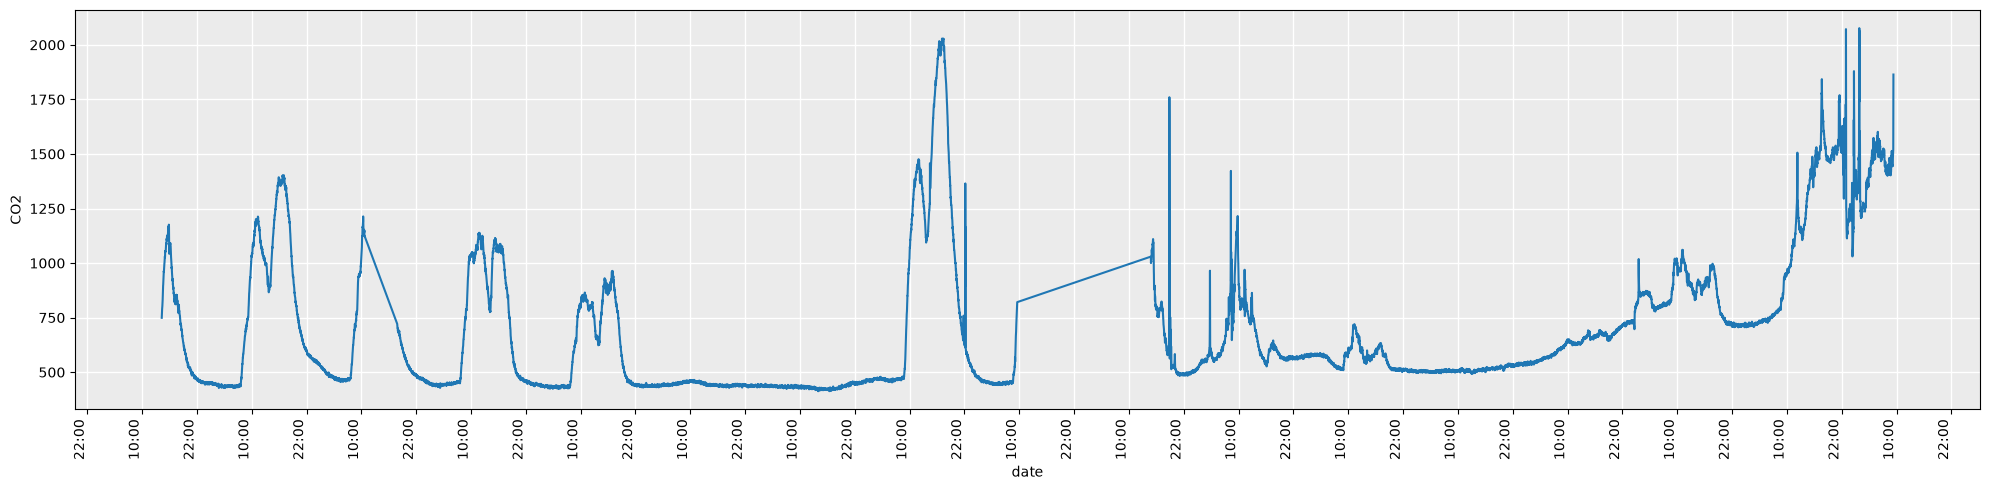

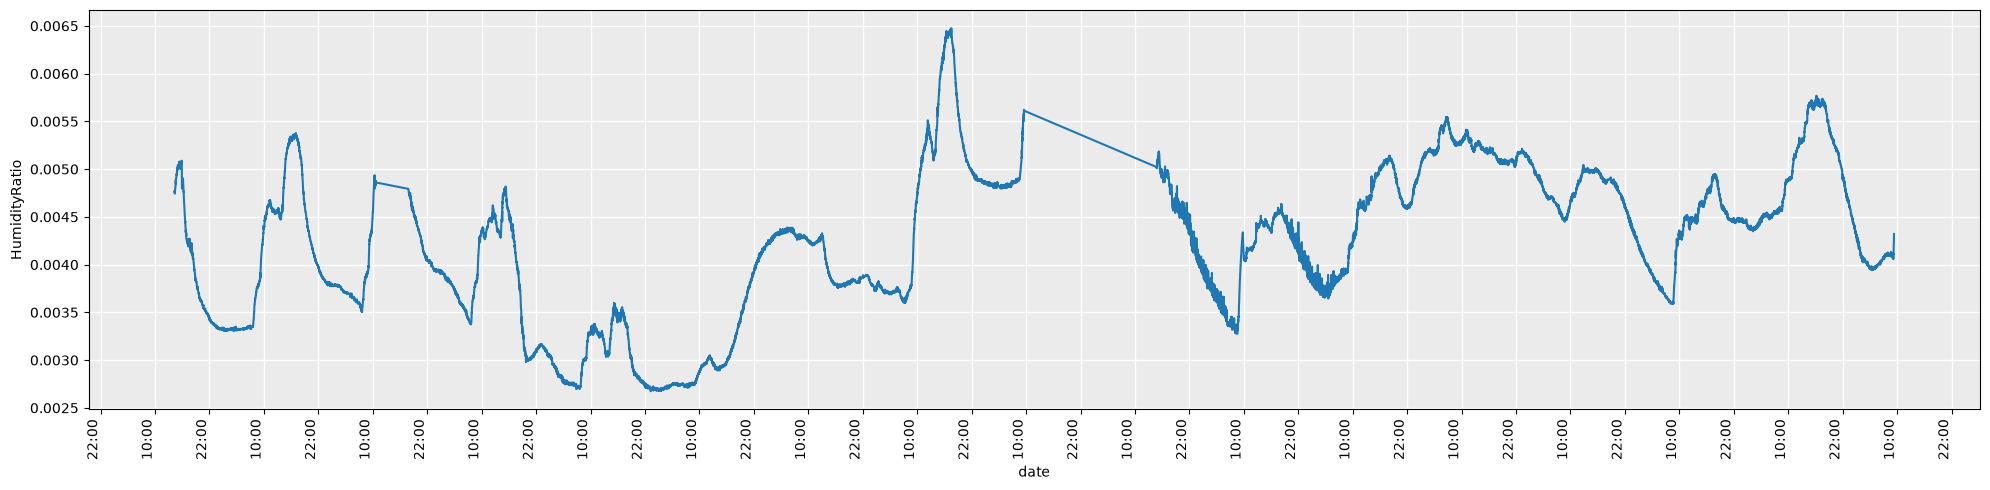

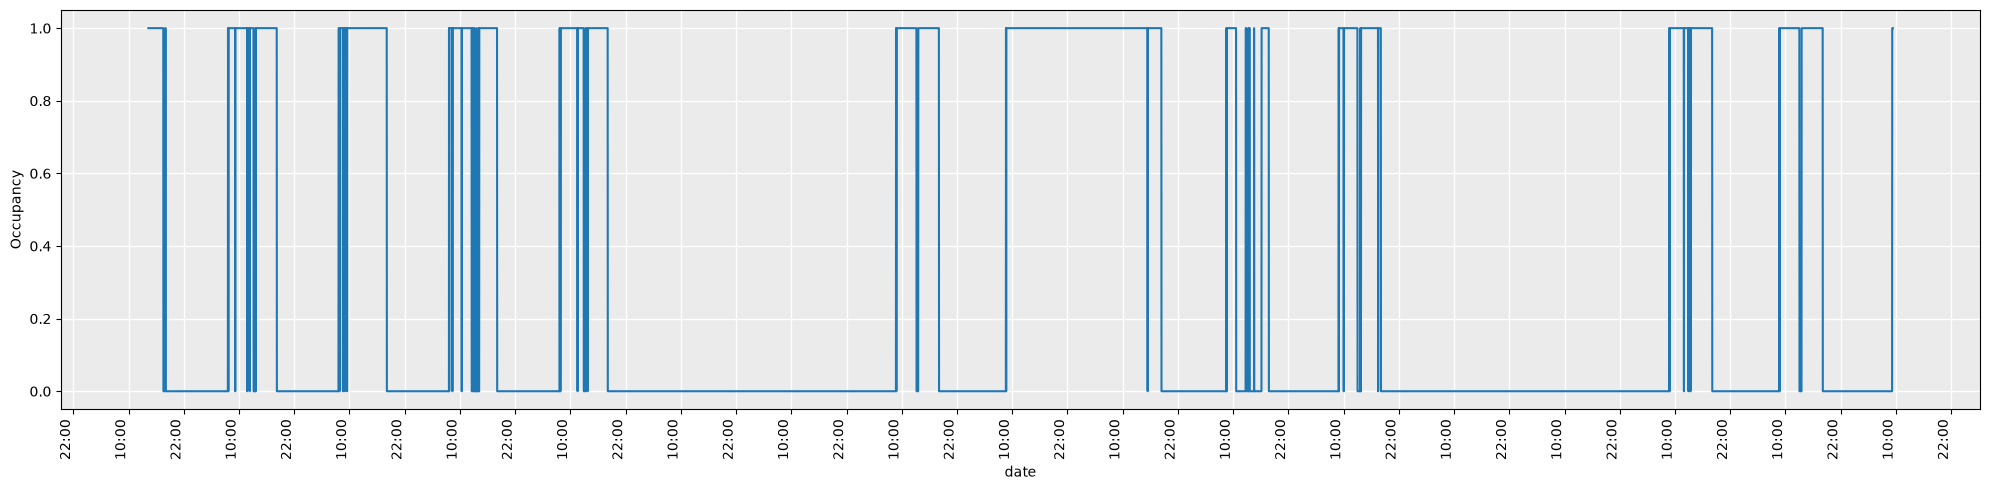

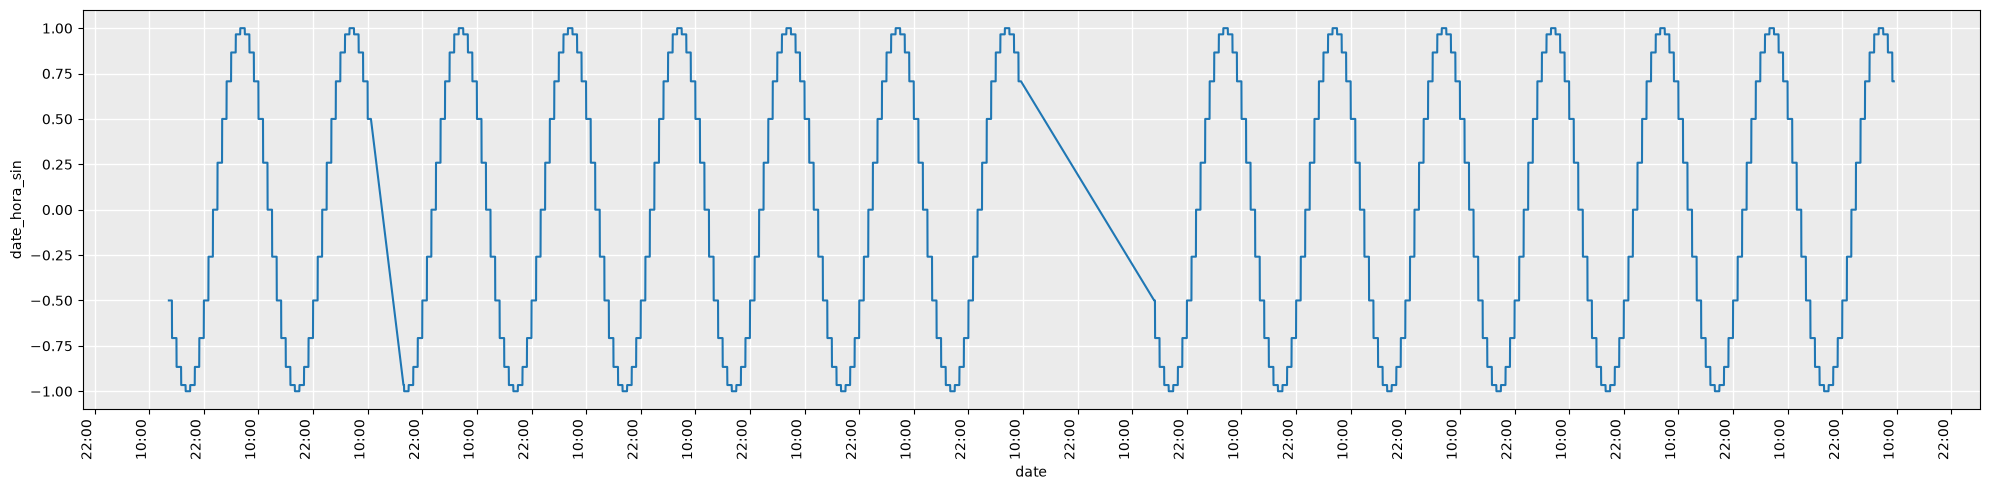

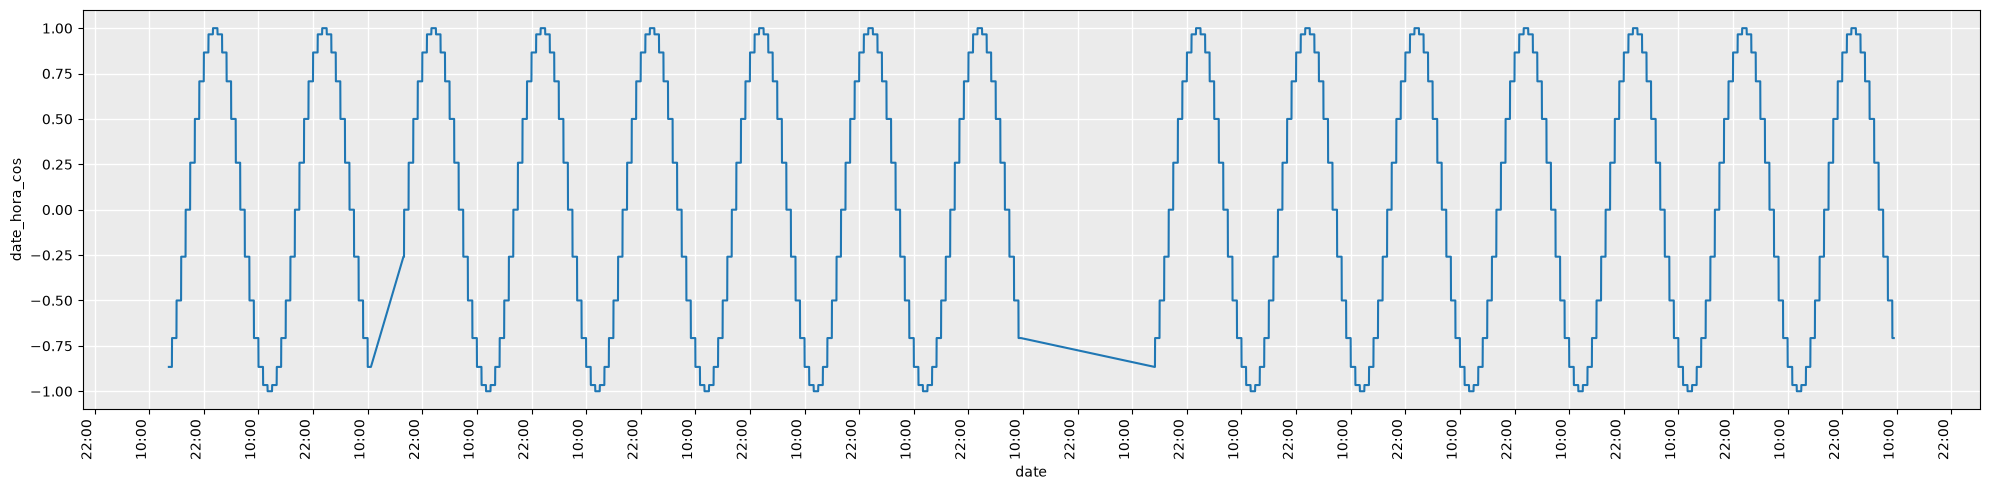

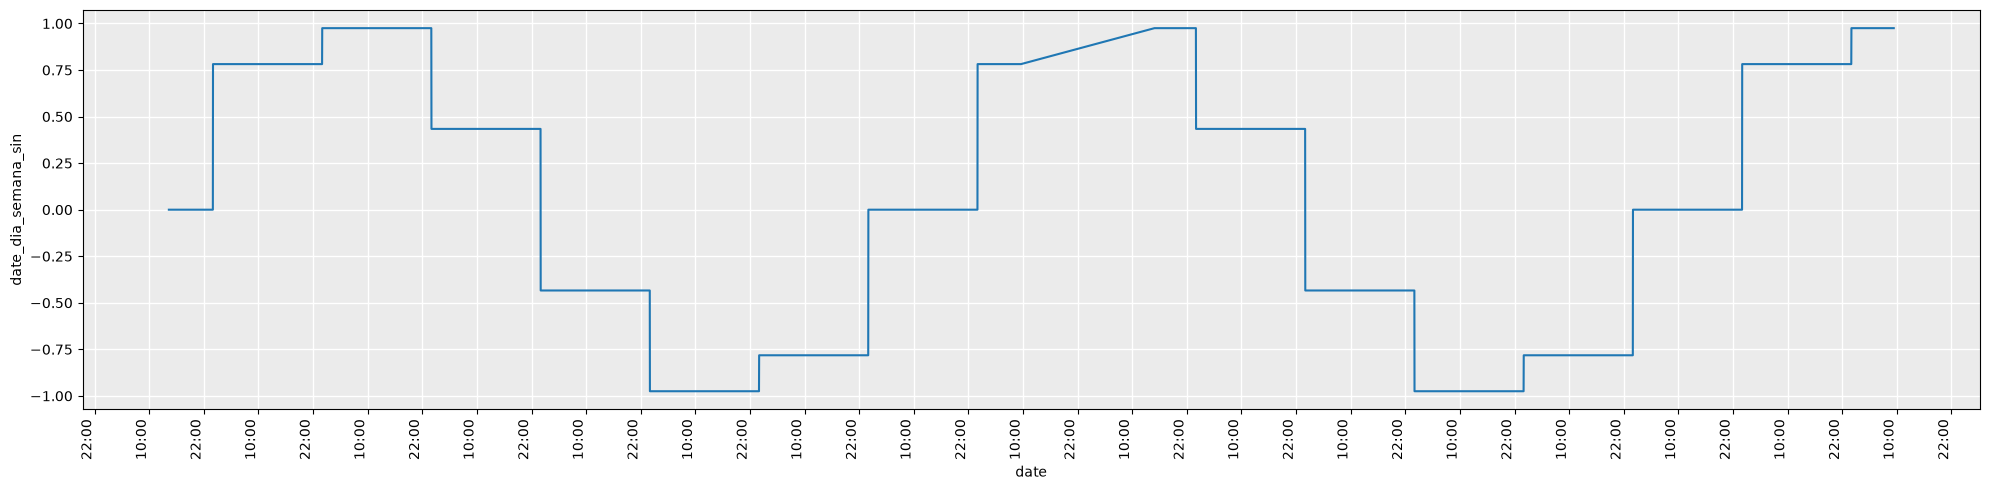

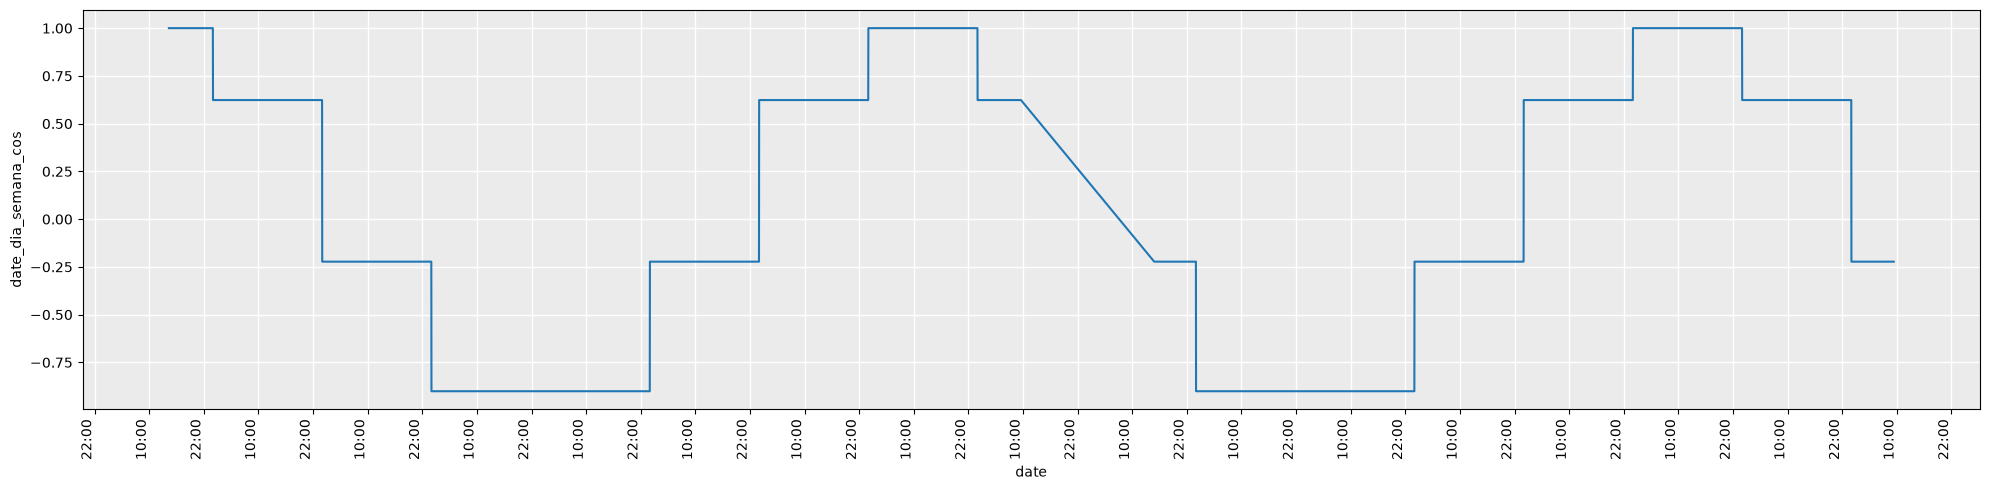

In [82]:
recorte = datatest[(datatest["date"] >= "2015-02-03 06:40:00") & (datatest["date"] <= "2015-02-04 10:15:00")]

plot_hora(dataset_completo, intervalo=12)
